# **Human Protein Atlas - Single Cell Classification**

___

<u>Background:</u> The Human Protein Atlas (HPA) is a Swedish-based initiative aimed to comprehensively map proteins in human cells, tissues, and organs — providing valuable data for scientists worldwide. The rapid advancements in microscopy technology have enabled the generation of an unprecedented number of microscopic images. However, this surge in image data production presents a substantial challenge, as extracting meaningful insights from this vast wealth of information becomes increasingly complex. To overcome this, there is a growing need for the development of automated image analysis techniques. These methods not only streamline and expedite the process but also enhance our understanding of fundamental aspects of cell biology. They hold the potential to efficiently interpret and extract valuable insights from the extensive repositories of images at our disposal. In particular, the study of single cells shows great promise in revealing cellular mechanisms that are often obscured in multi-cell research. 

<u>Introduction:</u> In 2018, the Kaggle-hosted Human Protein Atlas (HPA) Image Classification competition marked a significant milestone in the field of bioinformatics and image analysis. Challenging participants to develop innovative solutions for protein subcellular localization prediction with a focus on microscopy data, the competition aimed to advance our understanding of cell biology by automating the process of classifying mixed patterns of proteins in microscope images. In 2021, the Human Protein Atlas - Single Cell Classification competition continued to push the boundaries of automated image analysis. Dedicated to characterizing single-cell heterogeneity — the phenomenon of how genetically identical cells can show functional variation (i.e. in response to drug treatment) — in our large collection of images by generating more accurate annotations of the subcellular localizations for thousands of human proteins in individual cells, we will be able to further understand how human cells functions and how diseases develop.

<u>Problem Statement:</u> Although current machine learning models provide summaries of cell populations, further advancements are still required to accurately classify patterns within individual cells. Drawing upon pre-trained models from diverse knowledge domains — including machine learning, biomedical image informatics, and cellular biology — develop a novel strategy to overcome the difficulties encountered by existing models while enhancing both the interpretability and robustness of the newly proposed method.


<u>Objective:</u> Given a weakly labelled dataset of microscopy images, our goal is to develop a model capable of segmenting and classifying each individual cell with precise labels. 

<u>TLDR:</u> Find individual human cell differences in microscope images.

___

**Initialization and Set-up**

In [1]:
# Importing Python Libraries
import io
import os
import warnings
warnings.filterwarnings('ignore')
import requests
import pathlib
import gzip
import imageio
import seaborn as sns
import pandas as pd
import opendatasets as od
#%pip install -q kaggle --upgrade

import torch
import torchvision
from torchvision import datasets
import torchvision.transforms as transforms

import matplotlib.pyplot as plt
from matplotlib import colormaps
import random
import cv2
import numpy as np

from PIL import Image

# Machine Learning and Data Science Imports
import tensorflow as tf; print(f"\t\t– TENSORFLOW VERSION: {tf.__version__}");
import pandas as pd; pd.options.mode.chained_assignment = None;
import numpy as np; print(f"\t\t– NUMPY VERSION: {np.__version__}");

import glob
# from tqdm.notebook import tqdm
from tqdm import tqdm

		– TENSORFLOW VERSION: 2.14.0
		– NUMPY VERSION: 1.25.2


In [2]:
print(f"\t\t– PYTORCH VERSION: {torch.__version__}");
import sys
print(sys.version_info)

		– PYTORCH VERSION: 2.3.0.dev20240122+cu121
sys.version_info(major=3, minor=11, micro=5, releaselevel='final', serial=0)


In [3]:
# Check GPU status
!nvidia-smi

Sat Mar  2 12:00:55 2024       
+---------------------------------------------------------------------------------------+
| NVIDIA-SMI 546.26                 Driver Version: 546.26       CUDA Version: 12.3     |
|-----------------------------------------+----------------------+----------------------+
| GPU  Name                     TCC/WDDM  | Bus-Id        Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |         Memory-Usage | GPU-Util  Compute M. |
|                                         |                      |               MIG M. |
|=========================================+======================+======================|
|   0  NVIDIA GeForce RTX 4060 ...  WDDM  | 00000000:01:00.0 Off |                  N/A |
| N/A   43C    P5               9W /  90W |    143MiB /  8188MiB |     38%      Default |
|                                         |                      |                  N/A |
+-----------------------------------------+----------------------+--

In [4]:
# Check PyTorch can access GPU
print(torch.backends.cudnn.enabled)
print(torch.version)
torch.cuda.is_available()

True
<module 'torch.version' from 'c:\\Users\\szhan\\AppData\\Local\\Programs\\Python\\Python311\\Lib\\site-packages\\torch\\version.py'>


True

In [3]:
# PATH_OF_DATA = '/project/btec-design3/kaggle_dataset/train2021'               # SCC
PATH_OF_DATA = '../../train/data'                                                     # Local     
PATH_OF_CSV = '../../train/train.csv'

In [5]:
# All label names in the public HPA dataset and their corresponding index
all_locations = dict({
    "Nucleoplasm": 0,
    "Nuclear Membrane": 1,
    "Nucleoli": 2,
    "Nucleoli Fibrillar Center": 3,
    "Nuclear Speckles": 4,
    "Nuclear Bodies": 5,
    "Endoplasmic Reticulum": 6,
    "Golgi Apparatus": 7,
    "Intermediate Filaments": 8,
    "Actin Filaments": 9,
    # "Focal adhesion sites": 9,
    "Microtubules": 10,
    "Mitotic Spindle": 11,
    "Centrosome": 12,
    # "Centriolar satellite": 12,
    "Plasma Membrane": 13,
    # "Cell Junctions": 13,
    "Mitochondria": 14,
    "Aggresome": 15,
    "Cytosol": 16,
    # "Vesicles": 17,
    # "Peroxisomes": 17,
    # "Endosomes": 17,
    # "Lysosomes": 17,
    # "Lipid droplets": 17,
    # "Cytoplasmic bodies": 17,
    "Vesicles and Punctate Cytosolic Patterns": 17, 
    # "No staining": 18
    "Negative": 18
})

___

**Preliminary Exploratory Data Analysis (EDA)**

In [6]:
# Step 1: Data Loading and Overview

# Load the CSV file containing labels
# labels_df = pd.read_csv('/project/btec-design3/kaggle_dataset/train.csv')         # SCC               
labels_df = pd.read_csv(PATH_OF_CSV)                                          # Local     

# Get a high-level overview of the data
num_samples = len(labels_df)
num_classes = labels_df['Label'].nunique()

# Create a mapping between image file names and their labels
# Create a list to associate image file names with labels
image_data = []

# Iterate through the rows in the DataFrame
for index, row in labels_df.iterrows():
    image_file_name = row['ID']                                                         # Assuming 'ID' is the column containing the image file names
    label = row['Label']                                                                # Assuming 'Label' is the column containing the labels
    
    # Construct the full path to the image file
    image_path = os.path.join(PATH_OF_DATA, f'{image_file_name}.png')
    
    # Append the image file name and label to the list
    image_data.append([image_file_name, label])

# Create a new DataFrame from the list of image data
image_label_df = pd.DataFrame(image_data, columns=['ImageFileName', 'Label_idx'])
#print(image_label_df.head(10))

def add_label(df, all_locations):
    "Function to convert index to label name"
    #print(df.head())
    for i, row in df.iterrows():
        label_idx = row.Label_idx.split('|')
        #print(label_idx)
        labels = []
        for idx in label_idx:
            idx = int(idx)
            #print(idx in all_locations.values())
            if idx in all_locations.values():
                labels.append([key for key, value in all_locations.items() if value == idx][0])
                #print(labels)
        if len(labels)>0:
            df.loc[i,"Label"] = ",".join(labels)
        #print(df.loc[i,"Label"], df.loc[i, "Label_idx"])
        #print(df.head())
    return df

# Initialize the 'Label' column in DataFrame with placeholder value
image_label_df['Label'] = None
image_label_df = add_label(image_label_df, all_locations)


#print(image_label_df.head(10))

MAX_LABELS_PER_IMAGE = max([x.count("|")+1 for x in image_label_df.Label_idx.unique()])
print(f"\nThe Maximum Number of Labels Per Image is: {MAX_LABELS_PER_IMAGE}\n\n")

MIN_LABELS_PER_IMAGE = min([x.count("|")+1 for x in image_label_df.Label_idx.unique()])
print(f"\nThe Minimum Number of Labels Per Image is: {MIN_LABELS_PER_IMAGE}\n\n")

#print(image_label_df.describe())
#print(image_label_df.info())

# Remove images with no labels
for index, row in image_label_df.iterrows():
    if row['Label'] is None:
        print(f"The label for image at index {index} is None")
        image_label_df = image_label_df.dropna(subset=['Label'])

print(f'\nMissing values in each column of train.csv:\n{labels_df.isnull().sum()}\n\n')

print('\nUnique Values in each column of train.csv')
for col in labels_df:
    print(f'{col}: {labels_df[col].nunique()}')

print("\n")

#print(image_label_df.describe())
#print(image_label_df.info())

# Iterate through the files in the folder and obtain full image paths
train_paths = sorted([os.path.join(PATH_OF_DATA, filename) for filename in os.listdir(PATH_OF_DATA) if filename.lower().endswith(('.png', '.jpg', '.jpeg'))])

print(f"\nGiven that 4 training images compose one example (R, G, B, Y):")
print(f"\t– i.e. The first 4 training files that make up 1 training image are:")
for path in [x.rsplit('/',1)[1] for x in train_paths[:4]]: print(f"\t\t– {path}")
print(f"\n\n\nThe number of training images is {len(train_paths)} => {len(train_paths)//4} 4-channel images")



The Maximum Number of Labels Per Image is: 5



The Minimum Number of Labels Per Image is: 1



Missing values in each column of train.csv:
ID       0
Label    0
dtype: int64



Unique Values in each column of train.csv
ID: 21806
Label: 432



Given that 4 training images compose one example (R, G, B, Y):
	– i.e. The first 4 training files that make up 1 training image are:
		– data\000a6c98-bb9b-11e8-b2b9-ac1f6b6435d0_blue.png
		– data\000a6c98-bb9b-11e8-b2b9-ac1f6b6435d0_green.png
		– data\000a6c98-bb9b-11e8-b2b9-ac1f6b6435d0_red.png
		– data\000a6c98-bb9b-11e8-b2b9-ac1f6b6435d0_yellow.png



The number of training images is 87224 => 21806 4-channel images


In [14]:
"""
For visualization, we can blend the channels in the following way:
        - red = red + yellow
        - green = green + yellow/2
        - blue = blue
"""

def rgby_to_rgb(img):
    rgb = np.zeros_like(img[..., :-1])                          # initialize rgb of same dimensions as img
    rgb[..., 0] = img[..., 0] + img[..., 3]                     # red = red + yellow
    rgb[..., 1] = img[..., 1] + img[..., 3]/2                   # green = green + yellow/2
    rgb[..., 2] = img[..., 2]                                   # blue = blue

    return rgb

def load_image(img_id, img_dir):
    """ 
    Composes 4 Files to Create 1 Image
    """
    rgby = [
        np.asarray(Image.open(os.path.join(img_dir, img_id+f"_{c}.png")), np.uint8) for c in ["red", "green", "blue", "yellow"]
    ]

    return np.stack(rgby, axis = -1)

Length of image_paths:  21806


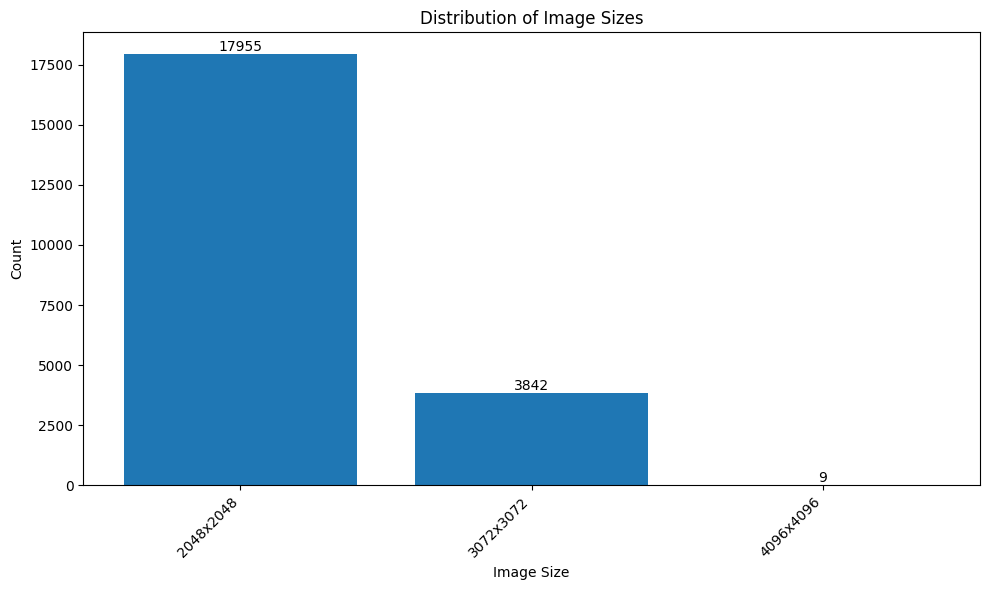

In [13]:
# Visualizing the image sizes in the dataset with their counts => not very efficient so don't run unless really necessary . . . better implementation further down in the notebook

# # Initialize a list to store image paths
# image_paths = []
# # Initialize a list to store image sizes
# image_sizes = []

# # Iterate through the files in the folder and obtain full image paths
# for filename in os.listdir(PATH_OF_DATA):
#     # Check if the file has a supported image extension
#     if filename.lower().endswith(('.png', '.jpg', '.jpeg')):
#         # Remove the suffixes (_red, _blue, _green, _yellow) from the file name
#         filename_without_suffix = os.path.splitext(filename)[0].rsplit('_', 1)[0]
#         # Construct the full path to the image file
#         image_path = os.path.join(PATH_OF_DATA, filename_without_suffix + os.path.splitext(filename)[1])
#         # Append the image path to the list
#         image_paths.append(image_path)

# image_paths = set(image_paths)

# # Sort the list of image paths
# image_paths = sorted(image_paths)
# print('Length of image_paths: ', len(image_paths))

# # Load each image, convert to RGB, and get its size
# for path in image_paths:
#     # Load image and convert to RGB
#     # print(os.path.splitext(os.path.basename(path))[0], PATH_OF_DATA)
#     rgby_image = load_image(os.path.splitext(os.path.basename(path))[0], PATH_OF_DATA)
#     rgb_image = rgby_to_rgb(rgby_image)
    
#     # Get the size of the image
#     height, width, _ = rgb_image.shape
    
#     # Store the size in a tuple (width, height)
#     image_sizes.append((width, height))

# # Count the occurrences of each unique image size
# from collections import Counter
# image_size_counts = Counter(image_sizes)

# # Create lists to store width, height, and counts
# widths = []
# heights = []
# counts = []

# # Extract width, height, and count for each unique image size
# for size, count in image_size_counts.items():
#     widths.append(size[0])
#     heights.append(size[1])
#     counts.append(count)

# # Plot the distribution of image sizes
# plt.figure(figsize = (10, 6))
# bars = plt.bar(range(len(widths)), counts, tick_label = [f"{w}x{h}" for w, h in zip(widths, heights)])

# # Add count values as text labels on top of each bar
# for bar, count in zip(bars, counts):
#     plt.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 0.5, str(count), ha = 'center', va = 'bottom')

# plt.xlabel('Image Size')
# plt.ylabel('Count')
# plt.title('Distribution of Image Sizes')
# plt.xticks(rotation = 45, ha = 'right')
# plt.tight_layout()
# plt.show()

Based on the results so far (confirmed by the information we were given), we know that:
<br>
    &emsp;- The training set is comprised of 21, 806 images
    <br>
    &emsp;- The images in this dataset are confocal microscopy images containing 4 channels (R, G, B, Y)
    <br>
    &emsp;&emsp;- Red (Microtubules)
        <br>
    &emsp;&emsp;- Green (Protein of Interest)
        <br>
    &emsp;&emsp;- Blue (Nucleus)
        <br>
    &emsp;&emsp;- Yellow (Endoplasmic Reticulum)
        <br>
    &emsp;- The images are a mix of resolutions (1728x1728, 2048x2048, and 3072x3072)
        <br>
    &emsp;- There are in total 19 different labels present in the dataset (18 labels for specific locations, and label 18 for negative and unspecific signal)
      <br>
    &emsp;&emsp;- The dataset comprises of 17 different cell types with highly different morphology => affects protein patterns of different organelles

Number of labels: 1, Percentage: 47.75%
Number of labels: 2, Percentage: 40.94%
Number of labels: 3, Percentage: 10.39%
Number of labels: 4, Percentage: 0.90%
Number of labels: 5, Percentage: 0.01%


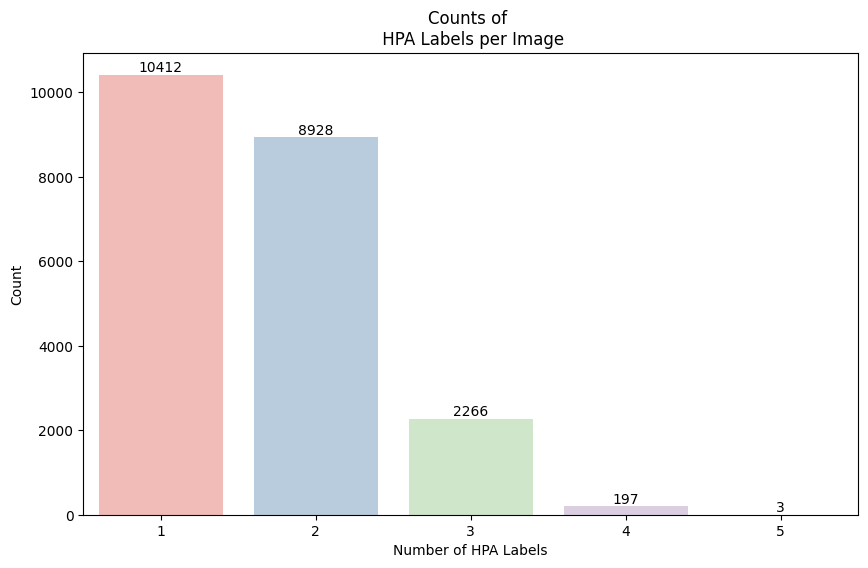

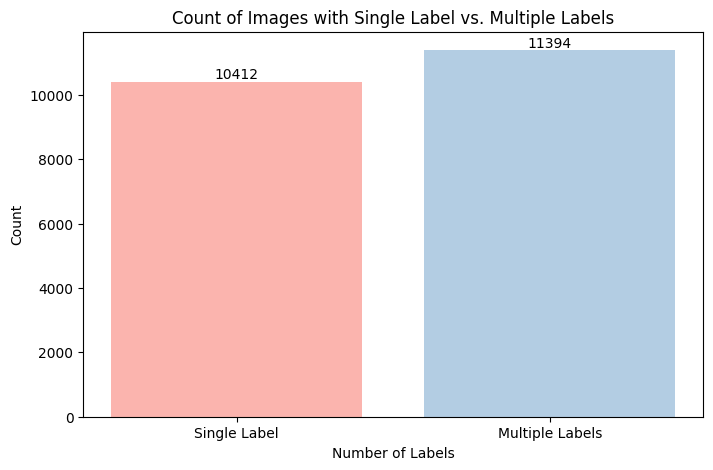

In [15]:
# Count the number of labels (comma-separated) for each entry
label_counts = image_label_df['Label'].str.count(',') + 1

# Calculate the percentage
label_percentages = (label_counts.value_counts() / len(label_counts)) * 100

# Print the percentage for each number of labels
for num_labels, percentage in label_percentages.sort_index().items():
    print(f"Number of labels: {num_labels}, Percentage: {percentage:.2f}%")

# Create a bar plot
plt.figure(figsize = (10, 6))
#ax = label_counts.value_counts().sort_index().plot(kind = 'bar')
ax = sns.barplot(x = label_percentages.index, y = label_counts.value_counts().sort_index(), palette = sns.color_palette("Pastel1"))
# plt.title("Counts of \n HPA Labels per Image", fontsize = 20, weight = 'bold')
# plt.xlabel("Number of HPA Labels", fontsize = 18, weight = 'bold')
# plt.ylabel("Count", fontsize = 18, weight = 'bold')
# plt.xticks(rotation = 0, fontsize = 16)
# plt.yticks(fontsize = 16)
# ax.bar_label(ax.containers[0], fontsize = 16, weight = 'bold')

plt.title("Counts of \n HPA Labels per Image")
plt.xlabel("Number of HPA Labels")
plt.ylabel("Count")
plt.xticks(rotation = 0)
ax.bar_label(ax.containers[0])

plt.show()


# Count the number of labels for images with only one label
single_label_counts = label_counts[label_counts == 1].count()

# Count the number of labels for images with two or more labels
multiple_label_counts = label_counts[label_counts >= 2].count()

#print(f"The number of images with single label is: {single_label_counts}")
#print(f"The number of images with mutliple labels is: {multiple_label_counts}")

# Create a bar plot to compare single vs. multiple labels
plt.figure(figsize = (8, 5))
#plt.bar(['Single Label', 'Multiple Labels'], [single_label_counts, multiple_label_counts])
plt.bar(['Single Label', 'Multiple Labels'], [single_label_counts, multiple_label_counts], color = sns.color_palette("Pastel1"))
# plt.xlabel("Number of Labels", fontsize = 20, weight = 'bold')
# plt.ylabel("Count", fontsize = 20, weight = 'bold')
# plt.title("Count of Images with Single Label vs. Multiple Labels", fontsize = 20, weight = 'bold')
# plt.yticks(fontsize = 16)
# plt.xticks(fontsize = 16)
# for i in range(len(['Single Label', 'Multiple Labels'])):
#     plt.text(i, [single_label_counts, multiple_label_counts][i], [single_label_counts, multiple_label_counts][i], ha='center', va='bottom', fontsize = 16, weight = 'bold')

plt.xlabel("Number of Labels")
plt.ylabel("Count")
plt.title("Count of Images with Single Label vs. Multiple Labels")
for i in range(len(['Single Label', 'Multiple Labels'])):
    plt.text(i, [single_label_counts, multiple_label_counts][i], [single_label_counts, multiple_label_counts][i], ha = 'center', va = 'bottom')


plt.show()

Per class count in train dataset:
-------------------------------------------------
The class Nucleoplasm has 8797 samples
The class Cytosol has 5685 samples
The class Plasma Membrane has 3216 samples
The class Nucleoli has 2451 samples
The class Mitochondria has 2013 samples
The class Golgi Apparatus has 1846 samples
The class Nuclear Bodies has 1792 samples
The class Centrosome has 1734 samples
The class Nuclear Speckles has 1425 samples
The class Nucleoli Fibrillar Center has 1262 samples
The class Nuclear Membrane has 1095 samples
The class Actin Filaments has 1011 samples
The class Intermediate Filaments has 964 samples
The class Microtubules has 818 samples
The class Endoplasmic Reticulum has 775 samples
The class Vesicles and Punctate Cytosolic Patterns has 621 samples
The class Aggresome has 252 samples
The class Mitotic Spindle has 78 samples
The class Negative has 34 samples


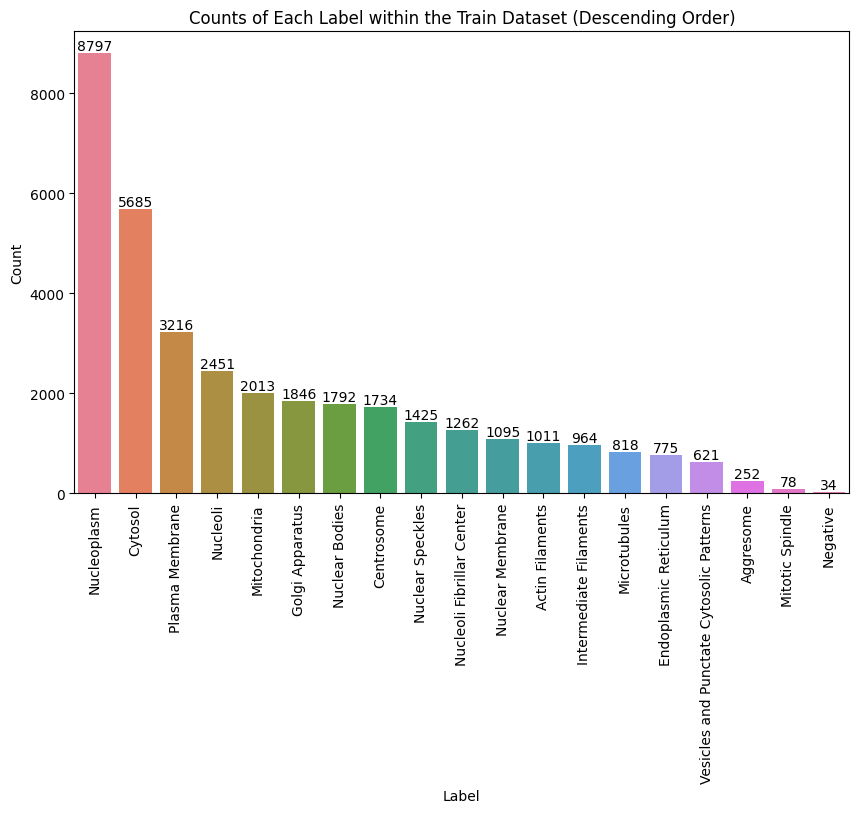

In [16]:
# List of the labels
labels_List = list(all_locations.keys())
#print(labels_List)

# Make a copy of master df
copy_image_label_df = image_label_df.copy()

# Split the labels by comma
copy_image_label_df['Label'] = image_label_df['Label'].str.split(',')
copy_image_label_df = (copy_image_label_df.explode('Label').groupby('Label'))

#print(copy_image_label_df.head(10))

label_counts = copy_image_label_df['Label'].value_counts()
label_counts_sorted = label_counts.sort_values(ascending = False)
#print(label_counts.head(10))
#print(label_counts_sorted.head(10))

print('Per class count in train dataset:')
print('-------------------------------------------------')
for label, count in label_counts_sorted.items():
    print(f"The class {label} has {count} samples")

# Create a bar plot in descending order
plt.figure(figsize=(10, 6))
#ax = label_counts_sorted.plot(kind = 'bar')
ax = sns.barplot(x = label_counts_sorted.index, y = label_counts_sorted, palette = sns.color_palette("husl", 19))
# plt.title("Counts of Each Label within the Train Dataset (Descending Order)", fontsize = 20, weight = 'bold')
# plt.xlabel("Label", fontsize = 20, weight = 'bold')
# plt.ylabel("Count", fontsize = 20, weight = 'bold')
# plt.yticks(fontsize = 16)
# plt.xticks(rotation = 90, fontsize = 16)   # Rotate x-axis labels for better readability
# ax.bar_label(ax.containers[0])

plt.title("Counts of Each Label within the Train Dataset (Descending Order)")
plt.xlabel("Label")
plt.ylabel("Count")
plt.xticks(rotation = 90)   # Rotate x-axis labels for better readability
ax.bar_label(ax.containers[0])

plt.show()

In [17]:
# Split the labels by comma based on whether the images are single label or multi-cell
# Count the number of labels (comma-separated) for each entry
label_counts = image_label_df['Label'].str.count(',') + 1
#print(label_counts)

single_list = []
multi_list = []
count = 0
for value in label_counts:
    if (value == 1):
        single_list.append(image_label_df['Label'].iloc[count])
    else:
        multi = image_label_df['Label'].iloc[count].split(',')
        multi_list = multi_list + multi
    count = count + 1

# # Create a bar plot in descending order
# plt.figure(figsize=(10, 6))
# ax = label_counts_sorted.plot(kind='bar')
# plt.title("Counts of Each Label within the Train Dataset (Descending Order)")
# plt.xlabel("Label")
# plt.ylabel("Count")
# plt.xticks(rotation = 90)   # Rotate x-axis labels for better readability
# ax.bar_label(ax.containers[0])
# plt.show()

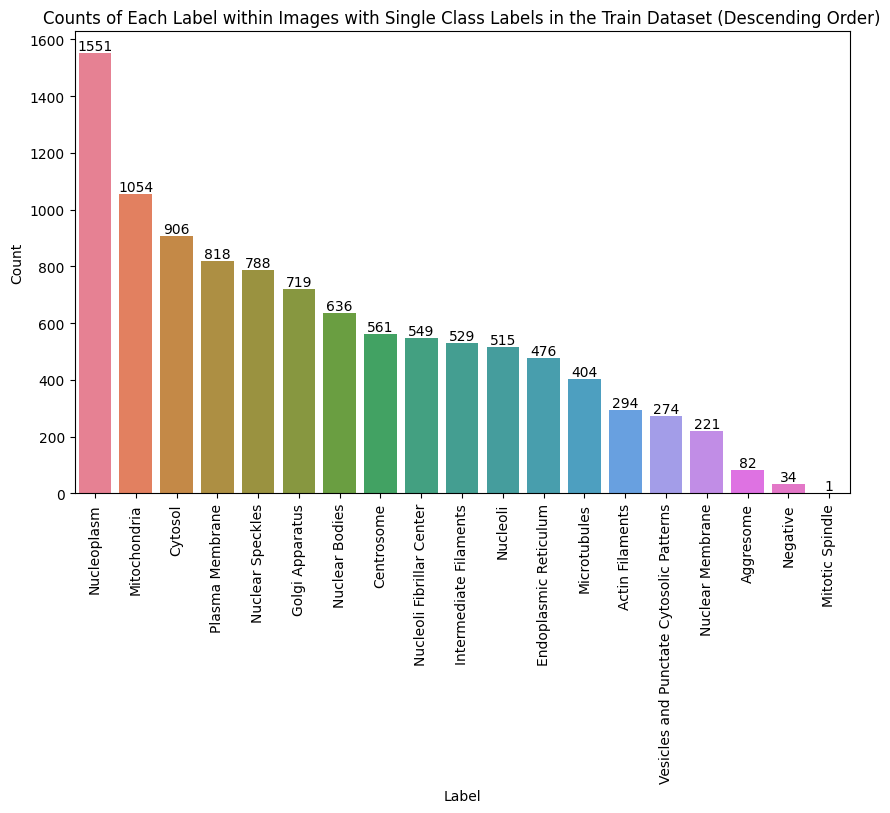

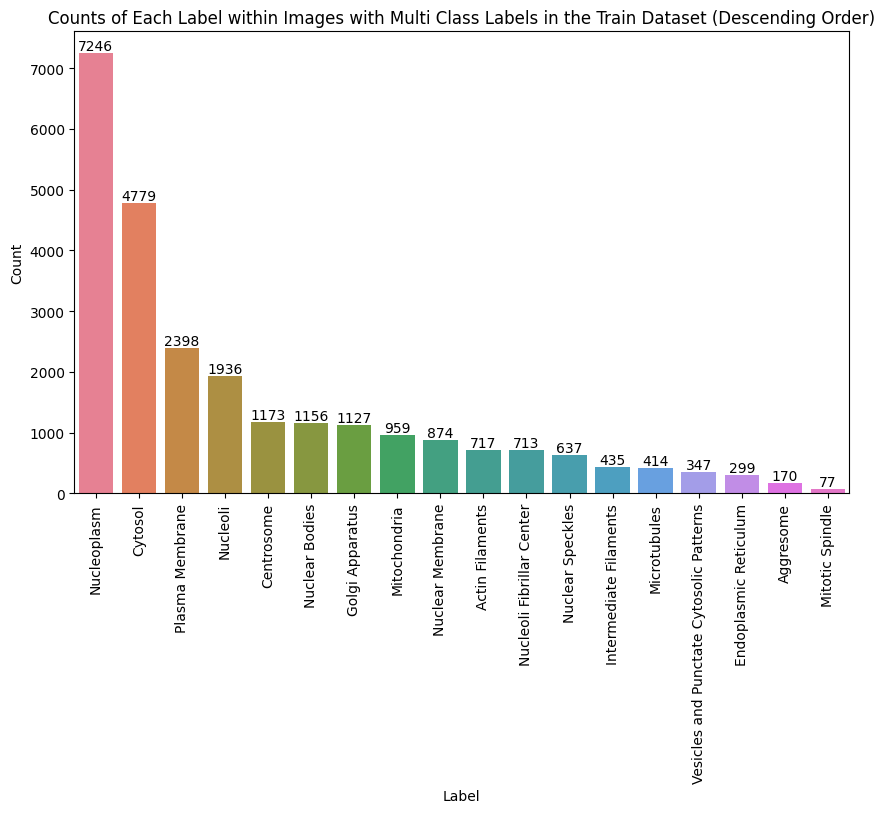

In [18]:
#print(single_list)
#print(len(multi_list))

count_single = pd.Series(single_list).value_counts()

# Create a bar plot in descending order
plt.figure(figsize=(10, 6))
#ax = count_single.plot(kind='bar')
ax = sns.barplot(x = count_single.index, y = count_single, palette = sns.color_palette("husl", 19))
# plt.title("Counts of Each Label within Images with Single Class Labels in the Train Dataset (Descending Order)", fontsize = 20, weight = 'bold')
# plt.xlabel("Label", fontsize = 20, weight = 'bold')
# plt.ylabel("Count", fontsize = 20, weight = 'bold')
# plt.yticks(fontsize = 16)
# plt.xticks(rotation = 90, fontsize = 16)   # Rotate x-axis labels for better readability
# ax.bar_label(ax.containers[0])

plt.title("Counts of Each Label within Images with Single Class Labels in the Train Dataset (Descending Order)")
plt.xlabel("Label")
plt.ylabel("Count")
plt.xticks(rotation = 90)   # Rotate x-axis labels for better readability
ax.bar_label(ax.containers[0])

plt.show()

count_multi = pd.Series(multi_list).value_counts()

# Create a bar plot in descending order
plt.figure(figsize=(10, 6))
#ax = count_multi.plot(kind='bar')
ax = sns.barplot(x = count_multi.index, y = count_multi, palette = sns.color_palette("husl", 19))
# plt.title("Counts of Each Label within Images with Multi Class Labels in the Train Dataset (Descending Order)", fontsize = 20, weight = 'bold')
# plt.xlabel("Label", fontsize = 20, weight = 'bold')
# plt.ylabel("Count", fontsize = 20, weight = 'bold')
# plt.yticks(fontsize = 16)
# plt.xticks(rotation = 90, fontsize = 16)   # Rotate x-axis labels for better readability
# ax.bar_label(ax.containers[0])

plt.title("Counts of Each Label within Images with Multi Class Labels in the Train Dataset (Descending Order)")
plt.xlabel("Label")
plt.ylabel("Count")
plt.xticks(rotation = 90)   # Rotate x-axis labels for better readability
ax.bar_label(ax.containers[0])

plt.show()

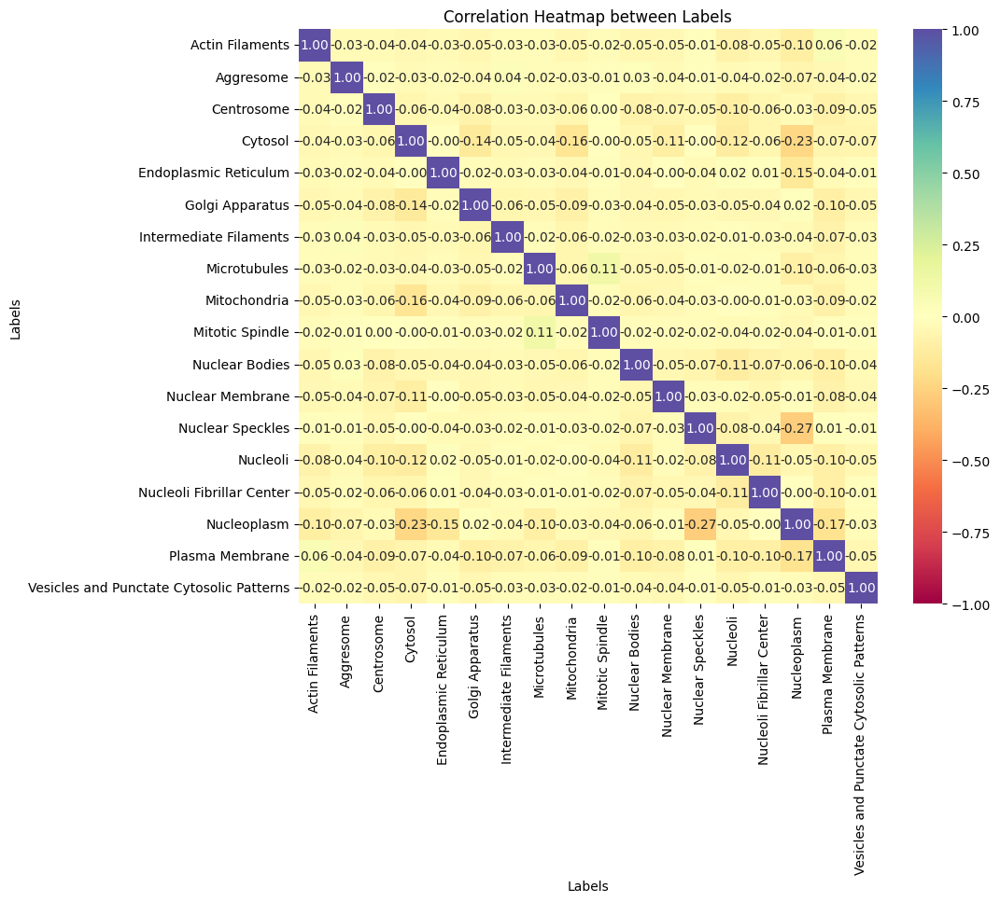

In [19]:
# multi_labeled_df = image_label_df[image_label_df['Label'].apply(len) > 1]
# print(multi_labeled_df)
# trial = multi_labeled_df.copy()
trial = image_label_df.copy()
trial['Label'] = trial['Label'].str.split(',')
multi_labeled_df = trial[trial['Label'].apply(len) > 1]
#print(multi_labeled_df)
#print(len(multi_labeled_df))
# Use pandas to expand the list of labels into separate rows
expanded_df = multi_labeled_df.explode('Label')
#print(expanded_df)
binary_matrix = pd.crosstab(index=expanded_df['ImageFileName'], columns=expanded_df['Label']).clip(upper=1)
#print(binary_matrix)

# Calculate the correlation matrix
correlation_matrix = binary_matrix.corr()
#print(correlation_matrix)

plt.figure(figsize=(10, 8))
sns.heatmap(correlation_matrix, cmap="Spectral", annot=True, fmt=".2f", vmin=-1, vmax=1)
# plt.title('Correlation Heatmap between Labels', fontsize = 20, weight = 'bold')
# plt.xlabel('Labels', fontsize = 20, weight = 'bold')
# plt.ylabel('Labels', fontsize = 20, weight = 'bold')

plt.title('Correlation Heatmap between Labels')
plt.xlabel('Labels')
plt.ylabel('Labels')

plt.show()


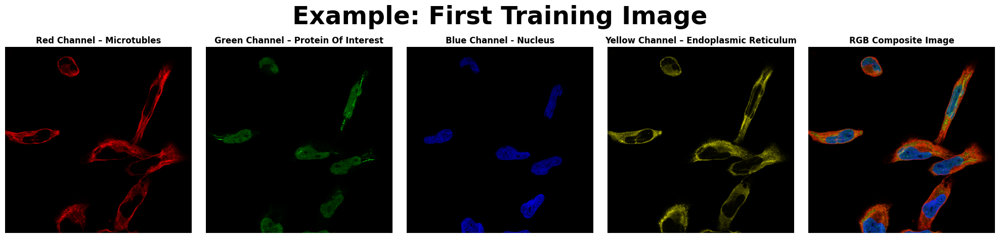

In [20]:
# Step 2: Image Visualization => convert 4 channel (R, G, B, Y) to 3 channel (R, G, B)

# """
# For visualization, we can blend the channels in the following way:
#         - red = red + yellow
#         - green = green + yellow/2
#         - blue = blue
# """

# def rgby_to_rgb(img):
#     rgb = np.zeros_like(img[..., :-1])                          # initialize rgb of same dimensions as img
#     rgb[..., 0] = img[..., 0] + img[..., 3]                     # red = red + yellow
#     rgb[..., 1] = img[..., 1] + img[..., 3]/2                   # green = green + yellow/2
#     rgb[..., 2] = img[..., 2]                                   # blue = blue

#     return rgb

# def load_image(img_id, img_dir):
#     """ 
#     Composes 4 Files to Create 1 Image
#     """
#     rgby = [
#         np.asarray(Image.open(os.path.join(img_dir, img_id+f"_{c}.png")), np.uint8) for c in ["red", "green", "blue", "yellow"]
#     ]

#     return np.stack(rgby, axis = -1)

# Visualize sample image => 1st image in train set
rgby_image = load_image(image_label_df.iloc[0].ImageFileName, img_dir = PATH_OF_DATA)
#print(rgby_image)
rgb_image = rgby_to_rgb(rgby_image)

# Display the sample image => 1st image in train set
plt.figure(figsize = (20, 6))
plt.subplot(1, 5, 5)
plt.title(f"RGB Composite Image", fontweight = "bold")
plt.imshow(rgb_image)
plt.axis(False)


for i, c in enumerate(["Red Channel – Microtubles", "Green Channel – Protein of Interest", "Blue Channel - Nucleus", "Yellow Channel – Endoplasmic Reticulum"]):
    channel_image = np.zeros_like(rgby_image[..., :-1])
    if c in ["Red Channel – Microtubles", "Green Channel – Protein of Interest", "Blue Channel - Nucleus"]:
        channel_image[..., i] = rgby_image[..., i]
    else:
        channel_image[..., 0] = rgby_image[..., i]
        channel_image[..., 1] = rgby_image[..., i]
    plt.subplot(1, 5, i + 1)
    plt.title(f"{c.title()}", fontweight = "bold")
    plt.imshow(channel_image)
    #print(ch_arr)
    plt.axis(False)

plt.suptitle("Example: First Training Image", fontsize = 35, fontweight = "bold")
plt.tight_layout(rect = [0, 0.2, 1, 0.97])
plt.show()


In [21]:
# # Stop Tensorflow From Eating All The Memory
# gpus = tf.config.experimental.list_physical_devices('GPU')
# if gpus:
#     try:
#         # Currently, memory growth needs to be the same across GPUs
#         for gpu in gpus:
#             tf.config.experimental.set_memory_growth(gpu, True)
#         logical_gpus = tf.config.experimental.list_logical_devices('GPU')
#         print(len(gpus), "... Physical GPUs,", len(logical_gpus), "Logical GPUs ...\n")
#     except RuntimeError as e:
#         # Memory growth must be set before GPUs have been initialized
#         print(e)

___

**Sampling the Dataset**

length original 21806
length toy 2091
Per class count in toy train dataset:
-------------------------------------------------
The class Nucleoplasm has 1034 samples
The class Cytosol has 681 samples
The class Plasma Membrane has 375 samples
The class Nucleoli has 253 samples
The class Golgi Apparatus has 196 samples
The class Centrosome has 194 samples
The class Nuclear Bodies has 190 samples
The class Mitochondria has 188 samples
The class Nucleoli Fibrillar Center has 169 samples
The class Nuclear Membrane has 129 samples
The class Nuclear Speckles has 122 samples
The class Actin Filaments has 111 samples
The class Intermediate Filaments has 94 samples
The class Vesicles and Punctate Cytosolic Patterns has 85 samples
The class Microtubules has 71 samples
The class Endoplasmic Reticulum has 69 samples
The class Aggresome has 31 samples
The class Mitotic Spindle has 8 samples
The class Negative has 2 samples


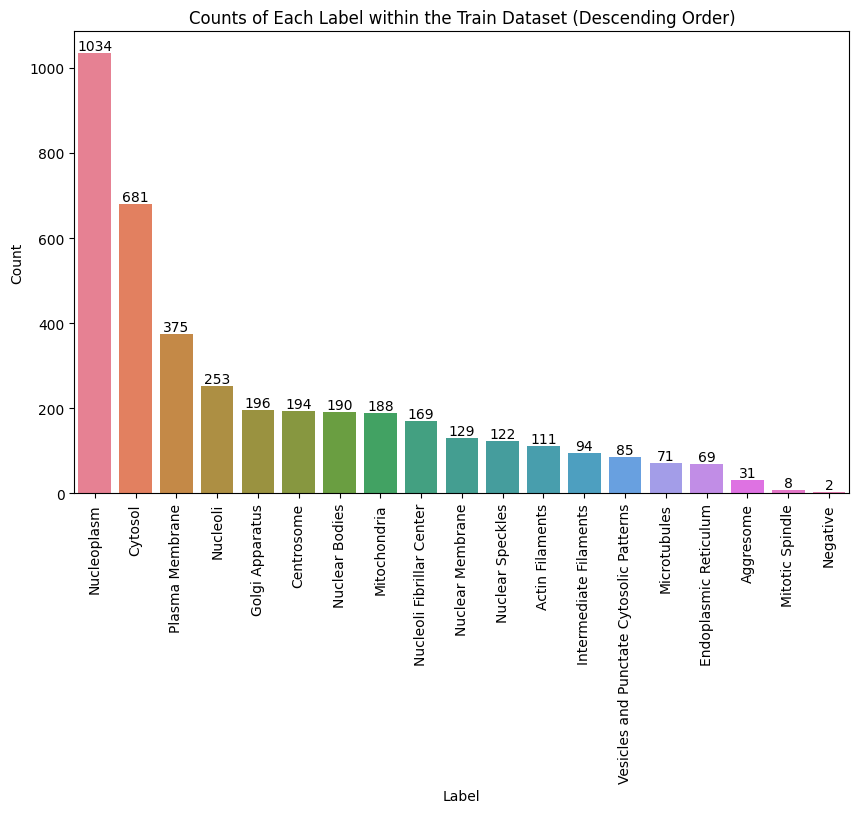

In [ ]:
def create_toy_dataset_multilabel(original_df, sample_size=0.2, random_state=None):
    # Get the labels and their distribution
    labels = original_df['Label'].apply(lambda x: x.split(','))
    all_labels = [label for sublist in labels for label in sublist]
    label_distribution = pd.Series(all_labels).value_counts(normalize=True)

    # Calculate the number of samples to keep for each label in the toy dataset
    label_sizes = (label_distribution * sample_size * len(original_df)).astype(int)

    # Initialize the toy dataset
    toy_df = pd.DataFrame(columns=original_df.columns)

    # Sample from each label to create the toy dataset
    for label, size in label_sizes.items():
        label_subset_indices = original_df[original_df['Label'].apply(lambda x: label in x)].sample(size, random_state=random_state).index
        toy_df = pd.concat([toy_df, original_df.loc[label_subset_indices]], ignore_index=True)

    return toy_df

# Example usage
sample_size = 0.1
toy_dataset_multilabel = create_toy_dataset_multilabel(image_label_df, sample_size = sample_size, random_state = 42)

toy_dataset_multilabel.drop_duplicates(subset = ['ImageFileName'], keep = 'first', inplace = True)

print("length original", len(image_label_df))
print("length toy", len(toy_dataset_multilabel))
#print(toy_dataset_multilabel)


# Make a copy of master df
copy_toy = toy_dataset_multilabel.copy()

# Split the labels by comma
copy_toy['Label'] = toy_dataset_multilabel['Label'].str.split(',')
copy_toy = (copy_toy.explode('Label').groupby('Label'))

#print(copy_image_label_df.head(10))

label_counts = copy_toy['Label'].value_counts()
label_counts_sorted = label_counts.sort_values(ascending = False)
#print(label_counts.head(10))
#print(label_counts_sorted.head(10))

print('Per class count in toy train dataset:')
print('-------------------------------------------------')
for label, count in label_counts_sorted.items():
    print(f"The class {label} has {count} samples")

# Create a bar plot in descending order
plt.figure(figsize = (10, 6))
#ax = label_counts_sorted.plot(kind = 'bar')
ax = sns.barplot(x = label_counts_sorted.index, y = label_counts_sorted, palette = sns.color_palette("husl", 19))
# plt.title("Counts of Each Label within the Train Dataset (Descending Order)", fontsize = 20, weight = 'bold')
# plt.xlabel("Label", fontsize = 20, weight = 'bold')
# plt.ylabel("Count", fontsize = 20, weight = 'bold')
# plt.yticks(fontsize = 16)
# plt.xticks(rotation = 90, fontsize = 16)   # Rotate x-axis labels for better readability
# ax.bar_label(ax.containers[0])

plt.title("Counts of Each Label within the Train Dataset (Descending Order)")
plt.xlabel("Label")
plt.ylabel("Count")
plt.xticks(rotation = 90)   # Rotate x-axis labels for better readability
ax.bar_label(ax.containers[0])

plt.show()

toy_dataset_multilabel.to_csv(r'train/toy_data/toy_data.csv', index = False)


In [97]:
import shutil

def copy_all_variants_to_folder(original_folder, toy_dataset, new_folder):
    # Create the new folder if it doesn't exist
    if not os.path.exists(new_folder):
        os.makedirs(new_folder)

    # Get the list of file names from the toy dataset
    base_file_names = toy_dataset['ImageFileName'].tolist()
    # print(len(base_file_names))
    # Copy all variants (red, blue, green, yellow) for each file name
    for base_name in base_file_names:
        for variant in ['red', 'blue', 'green', 'yellow']:
            source_path = os.path.join(original_folder, f"{base_name}_{variant}.png")
            destination_path = os.path.join(new_folder, f"{base_name}_{variant}.png")

            try:
                shutil.copyfile(source_path, destination_path)
            except FileNotFoundError:
                print(f"File not found: {source_path}")

# Example usage
original_images_folder = PATH_OF_DATA
new_images_folder = 'train/toy_data'

copy_all_variants_to_folder(original_images_folder, toy_dataset_multilabel, new_images_folder)


___

**HPA Cell Segmenation**

In [18]:
# Step 3: Cell Segmentation => identify precise boundary of every cell in image

# Installing the segmentation tool
#%pip install https://github.com/CellProfiling/HPA-Cell-Segmentation/archive/master.zip
%pip install https://github.com/CellProfiling/HPA-Cell-Segmentation/archive/master.zip

# Cell Segmentation
try:
    import hpacellseg.cellsegmentator as cellsegmentator
    from hpacellseg.utils import label_cell, label_nuclei
except:
    %pip install -q "/kaggle/input/pycocotools/pycocotools-2.0-cp37-cp37m-linux_x86_64.whl"
    %pip install -q "/kaggle/input/hpapytorchzoozip/pytorch_zoo-master"
    %pip install -q "/kaggle/input/hpacellsegmentatormaster/HPA-Cell-Segmentation-master"
    import hpacellseg.cellsegmentator as cellsegmentator
    from hpacellseg.utils import label_cell, label_nuclei

from imageio import imwrite

#save_dir = 'train/segmented'

save_dir = os.path.join(os.getcwd(), 'train/toy_data')
if not os.path.exists(save_dir):
    os.makedirs(save_dir)

mt = glob.glob(save_dir + '/' + '*_red.png')
er = [f.replace('red', 'yellow') for f in mt]
nu = [f.replace('red', 'blue') for f in mt]
images = [mt, er, nu]

import hpacellseg.cellsegmentator as cellsegmentator
from hpacellseg.utils import label_cell, label_nuclei



[notice] A new release of pip is available: 23.3.1 -> 23.3.2
[notice] To update, run: python.exe -m pip install --upgrade pip


     - 0 bytes ? 0:00:00
     - 18.6 kB ? 0:00:00
  Preparing metadata (setup.py): started
  Preparing metadata (setup.py): finished with status 'done'
  Using cached https://github.com/haoxusci/pytorch_zoo/archive/master.zip
  Preparing metadata (setup.py): started
  Preparing metadata (setup.py): finished with status 'done'
Note: you may need to restart the kernel to use updated packages.


In [19]:
NUC_MODEL = "./train/toy_data/nuclei-model.pth"
CELL_MODEL = "./train/toy_data/cell-model.pth"

segmentator = cellsegmentator.CellSegmentator(
    NUC_MODEL,
    CELL_MODEL,
    scale_factor = 0.25,
    device = "cuda",
    padding = False,
    multi_channel_model = True,
)

please compile abn


In [20]:
# For nuclei
nuc_segmentations = segmentator.pred_nuclei(images[2])

# For full cells
cell_segmentations = segmentator.pred_cells(images)

# post-processing
for i, pred in enumerate(cell_segmentations):
    nuclei_mask, cell_mask = label_cell(nuc_segmentations[i], cell_segmentations[i])
    FOVname = os.path.basename(mt[i]).replace('red', 'predictedmask')
    imageio.imwrite(os.path.join(save_dir, FOVname), cell_mask) 

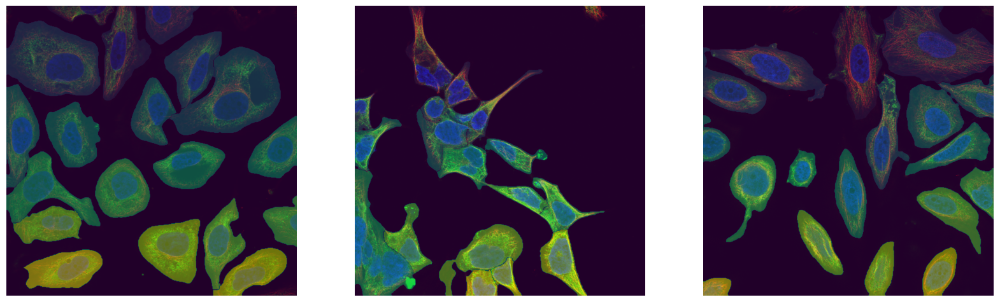

In [23]:
# Visualizing the segmentation masks we just predicted above

# import numpy as np
# import matplotlib.pyplot as plt

fig, ax = plt.subplots(1, 3, figsize = (20, 50))
for i in range(3):
    microtubule = plt.imread(mt[i])    
    endoplasmicrec = plt.imread(er[i])    
    nuclei = plt.imread(nu[i])
    mask = plt.imread(mt[i].replace('red','predictedmask'))
    # print(mt[i])
    # print(er[i])
    # print(nu[i])
    img = np.dstack((microtubule, endoplasmicrec, nuclei))
    ax[i].imshow(img)
    ax[i].imshow(mask, alpha=0.5)
    ax[i].axis('off')
plt.show()

In [86]:
from skimage.measure import regionprops
from tqdm import tqdm

# Extract file names
file_names = [os.path.basename(mt[i]).split('_red.png')[0] for i in range(len(mt))]

for i in tqdm(range(len(mt))):
    microtubule = plt.imread(mt[i])    
    endoplasmicrec = plt.imread(er[i])    
    nuclei = plt.imread(nu[i])
    mask = plt.imread(mt[i].replace('red', 'predictedmask'))

    original_image = np.dstack((microtubule, endoplasmicrec, nuclei))
    
    # fig, ax = plt.subplots(1, 4, figsize = (15, 20))
    # fig.suptitle(f'Image {i + 1} with Segmentation Masks', fontsize = 20, fontweight = 'bold', y = 0.61)  

    # ax[0].imshow(original_image)
    # ax[0].set_title(f'Original Image {i+1}', size = 16)
    # ax[0].axis('off')

    # ax[1].imshow(original_image)
    # ax[1].imshow(mask, alpha=0.5)
    # ax[1].set_title(f'Overlayed Original Image with Cell Mask', size = 16)
    # ax[1].axis('off')

    # # Cell mask
    cell_mask = label_cell(nuc_segmentations[i], cell_segmentations[i])[1]
    # ax[2].imshow(original_image)
    # ax[2].imshow(cell_segmentations[i], alpha = 0.5, cmap='viridis')
    # ax[2].set_title(f'Cell Mask', size = 16)
    # ax[2].axis('off')

    # # Nuclei mask
    # ax[3].imshow(original_image)
    # ax[3].imshow(nuc_segmentations[i], alpha = 0.5, cmap='viridis')
    # ax[3].set_title(f'Nuclei Mask', size = 16)
    # ax[3].axis('off')

    # # Show the plot
    # plt.tight_layout()
    # plt.show()

    # Visualizing each segmented cell individually

    # Unique vector of cell_mask numbers
    numbers = set(np.ravel(cell_mask))
    numbers.remove(0)

    # fig = plt.figure(figsize = (20, len(numbers)))
    # index = 1
    # fig.suptitle(f'Segmented Mask and Individual Cells of Image {i + 1}', fontsize = 20, fontweight = 'bold', y = 0.90)

    # ax = fig.add_subplot(len(numbers)//5+1, 5, index)
    # ax.set_title("Complete Cell Mask", size = 16)
    # plt.imshow(cell_mask)

    # Define the directory to save individual cell images
    save_dir = os.path.join("train/toy_data", file_names[i])
    # save_dir = "train/toy_data/individual_cells"
    os.makedirs(save_dir, exist_ok = True)

    index += 1
    for number in numbers:
        isolated_cell = np.where(cell_mask == number, cell_mask, 0)
        # ax = fig.add_subplot(len(numbers)//5+1, 5, index)
        # ax.set_title(f"Segment {number}", size = 16)
        # plt.imshow(isolated_cell)

        # Save the cell image to a directory named after the cell index
        seg_dir = os.path.join(save_dir, f"Segment_{number}.png")
        # os.makedirs(cell_dir, exist_ok = True)
        # cell_filename = os.path.join(cell_dir, "cell_image.png")
        plt.imsave(seg_dir, isolated_cell)

        index += 1

    # Crop segmentated cells from given images

    # Extract individual cells using regionprops
    regions = regionprops(cell_mask)                                                                                    # use skimage.measure.regionprops to extract individual regions (cells) from the labeled cell mask

    # # Plot each cell individually
    # fig, ax = plt.subplots(figsize = (10, 10))
    # ax.imshow(original_image)

    for region in regions:                                                                                              # iterate over each region and plot a rectangle around it using plt.Rectangle
        minr, minc, maxr, maxc = region.bbox
        rect = plt.Rectangle((minc, minr), maxc - minc, maxr - minr, fill = False, edgecolor = 'red', linewidth = 2)
        ax.add_patch(rect)

    # ax.set_title(f'Individual Cells of Image {i + 1}', fontsize = 20, fontweight = 'bold')
    # ax.axis('off')
    # plt.show()

    # Define the directory to save individual cell images
    save_dir = os.path.join("train/toy_data", file_names[i])
    # save_dir = "train/toy_data/individual_cells"
    os.makedirs(save_dir, exist_ok = True)

    # Extract individual cells using regionprops
    regions = regionprops(cell_mask)

    # Initialize lists to store cell properties
    cell_features = []
    cell_images = []

    # Create a figure to plot the segmented cells and their features
    numbers = set(np.ravel(cell_mask))
    numbers.remove(0)
    # fig = plt.figure(figsize = (20, len(numbers)))
    index = 1
    # fig.suptitle(f'Cropped Cells of Image {i + 1}', fontsize = 20, fontweight = 'bold', y = 0.91)

    # ax = fig.add_subplot(len(numbers)//5+1, 5, index)
    # plt.imshow(original_image)
    # ax.set_title("Original Image", size = 16)
    # ax.axis('off')

    index += 1

    # Iterate over each region and extract features
    for idx, region in enumerate(regions):
        # Extract features from the region (cell)
        area = region.area
        perimeter = region.perimeter
        
        # Append features to the list
        cell_features.append([area, perimeter])
        
        # Extract coordinates of the region (cell)
        minr, minc, maxr, maxc = region.bbox
        cell_image = original_image[minr:maxr, minc:maxc]
        cell_images.append(cell_image)
        
        # Save the cell image to a directory named after the cell index
        cell_dir = os.path.join(save_dir, f"Cell_{idx + 1}.png")
        # os.makedirs(cell_dir, exist_ok = True)
        # cell_filename = os.path.join(cell_dir, "cell_image.png")
        plt.imsave(cell_dir, cell_image)

        # # Plot the segmented cell and its features
        # ax = fig.add_subplot(len(numbers)//5+1, 5, index)
        # plt.imshow(cell_image)
        # ax.set_title(f"Cell {idx + 1}", size = 16)
        # ax.axis('off')
        # index += 1

    # Convert the list of cell features into a DataFrame
    cell_features_df = pd.DataFrame(cell_features, columns=['Area', 'Perimeter'])

    # Extracting and cropping each cell using a binary mask

    def extract_segmented_cells(original_image, segmentation_mask, i):
        # Convert the segmentation mask to a binary mask (0 or 255)
        binary_mask = (segmentation_mask > 0).astype(np.uint8) * 255

        # Find contours in the binary mask
        _, contours, _ = cv2.findContours(binary_mask, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)                                                          # _, contours, _ instead of contours, _ due to new update

        # Calculate the number of cells
        num_cells = len(contours)

        # # Calculate the number of rows and columns for subplots
        # num_cols = min(num_cells, 4)
        # num_rows = (num_cells + num_cols - 1) // num_cols

        # # Create a subplot grid
        # fig, axes = plt.subplots(num_rows, num_cols, figsize=(num_cols * 5, num_rows * 5))
        # fig.suptitle(f'Cropped Cells of Image {i + 1} using Binary Mask', fontsize = 20, fontweight = 'bold', y = 0.99)

        # # Flatten the axes array if it's a single row or column
        # if num_rows == 1:
        #     axes = axes.reshape(1, -1)
        # elif num_cols == 1:
        #     axes = axes.reshape(-1, 1)

        # # Display the original image
        # axes[0, 0].imshow(original_image)
        # axes[0, 0].set_title("Original Image", size = 16)
        # axes[0, 0].axis('off')

        # Iterate over each segmented cell
        for i, contour in enumerate(contours):
            # # Calculate the row and column index for the current cell
            # row = i // num_cols
            # col = i % num_cols

            # Create a blank mask to store the segmented cell
            segmented_cell_mask = np.zeros_like(binary_mask)

            # Draw contours of the segmented cell on the mask
            cv2.drawContours(segmented_cell_mask, [contour], -1, (255), thickness=cv2.FILLED)

            # print("Original Image Shape:", original_image.shape)
            # print("Mask Shape:", binary_mask.shape)
            # print("Segmentation Shape:", segmentation_mask.shape)

            # Apply the segmented cell mask on each channel of the original image
            segmented_cell = np.zeros_like(original_image)
            for c in range(original_image.shape[2]):
                segmented_cell[:, :, c] = cv2.bitwise_and(original_image[:, :, c], original_image[:, :, c], mask = segmented_cell_mask)

            # Get the bounding box of the segmented cell
            x, y, w, h = cv2.boundingRect(contour)

            # Crop the segmented cell from the resulting image
            cropped_cell = segmented_cell[y:y+h, x:x+w]

            # Save the segmented cell as an individual image file
            cell_filename = os.path.join(save_dir, f"Cell_Segment_{i + 1}.png")
            plt.imsave(cell_filename, cropped_cell)

        #     # Display the cropped cell in a subplot
        #     axes[row, col].imshow(cropped_cell)
        #     axes[row, col].set_title(f"Cropped Cell {i+1}", size = 16)
        #     axes[row, col].axis('off')

        # axes[row, col + 1].imshow(original_image)
        # axes[row, col + 1].axis('off')
        # axes[row, col + 1].set_title(f"Original Image", size = 16)

        # # Hide any remaining subplot cells
        # for i in range(num_cells, num_rows * num_cols):
        #     row = i // num_cols
        #     col = i % num_cols
        #     axes[row, col].axis('off')

        # plt.tight_layout()
        # plt.show()

    # Extract and display cropped cells
    extract_segmented_cells(original_image, cell_mask, i)


  0%|          | 0/2091 [00:00<?, ?it/s]100%|██████████| 2091/2091 [43:05:21<00:00, 74.19s/it]      


In [31]:
# def extract_segmented_cells(original_image, segmentation_mask, output_folder):
#     # Convert the segmentation mask to a binary mask (0 or 255)
#     binary_mask = (segmentation_mask > 0).astype(np.uint8) * 255

#     # Find contours in the binary mask
#     contours, _ = cv2.findContours(binary_mask, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)

#     # # Create the output folder if it doesn't exist
#     # if not os.path.exists(output_folder):
#     #     os.makedirs(output_folder)

#     # Calculate the number of rows and columns for subplots
#     num_cells = len(contours)
#     num_rows = (num_cells + 3) // 4
#     num_cols = min(num_cells, 4)

#     # Create a subplot grid
#     fig, axes = plt.subplots(num_rows, num_cols, figsize = (12, 3 * num_rows), sharex = False, sharey = False)

#     # Iterate over each segmented cell
#     for i, contour in enumerate(contours):
#         row = i // 4
#         col = i % 4

#         # Create a blank mask to store the segmented cell
#         segmented_cell_mask = np.zeros_like(binary_mask)

#         # Draw contours of the segmented cell on the mask
#         cv2.drawContours(segmented_cell_mask, [contour], -1, (255), thickness = cv2.FILLED)

#         # Apply the segmented cell mask on the original image
#         segmented_cell = cv2.bitwise_and(original_image, original_image, mask = segmented_cell_mask)

#         # # Save the segmented cell as an individual image file
#         # cell_filename = os.path.join(output_folder, f"cell_{i}.png")
#         # cv2.imwrite(cell_filename, segmented_cell)

#         # Display the segmented cell in the subplot grid
#         if num_cells == 1:
#             axes.imshow(segmented_cell)
#             axes.axis('off')
#             axes.set_title(f"Cell {i+1}")
#         else:
#             axes[row, col].imshow(segmented_cell)
#             axes[row, col].axis('off')
#             axes[row, col].set_title(f"Cell {i+1}")

#     # Hide any remaining subplot cells
#     for i in range(num_cells, num_rows * num_cols):
#         row = i // num_cols
#         col = i % num_cols
#         axes[row, col].axis('off')

#     plt.tight_layout()
#     plt.show()

# output_folder = "segmented_cells"

# # Extract and display segmented cells as subplots
# extract_segmented_cells(original_image, cell_mask, output_folder)


In [73]:
# # Visualizing each segmented cell individually - Example using Image 3

# # Unique vector of cell_mask numbers
# numbers = set(np.ravel(cell_mask))
# numbers.remove(0)

# fig = plt.figure(figsize = (20, len(numbers)))
# index = 1

# ax = fig.add_subplot(len(numbers)//5+1, 5, index)
# ax.set_title("Complete Cell Mask", size = 16)
# plt.imshow(cell_mask)

# # Define the directory to save individual cell images
# save_dir = os.path.join("train/toy_data", file_names[2])
# # save_dir = "train/toy_data/individual_cells"
# os.makedirs(save_dir, exist_ok = True)

# index += 1
# for number in numbers:
#     isolated_cell = np.where(cell_mask == number, cell_mask, 0)
#     ax = fig.add_subplot(len(numbers)//5+1, 5, index)
#     ax.set_title(f"Segment {number}", size = 16)
#     plt.imshow(isolated_cell)

#     # Save the cell image to a directory named after the cell index
#     seg_dir = os.path.join(save_dir, f"Segment_{number}.png")
#     # os.makedirs(cell_dir, exist_ok = True)
#     # cell_filename = os.path.join(cell_dir, "cell_image.png")
#     plt.imsave(seg_dir, isolated_cell)

#     index += 1

In [74]:
# # Crop segmentated cells from given images

# from skimage.measure import regionprops

# # Assuming cell_mask is the labeled cell mask
# # Extract individual cells using regionprops
# regions = regionprops(cell_mask)                                                                                    # use skimage.measure.regionprops to extract individual regions (cells) from the labeled cell mask

# # Plot each cell individually
# fig, ax = plt.subplots(figsize = (10, 10))
# ax.imshow(original_image)

# for region in regions:                                                                                              # iterate over each region and plot a rectangle around it using plt.Rectangle
#     minr, minc, maxr, maxc = region.bbox
#     rect = plt.Rectangle((minc, minr), maxc - minc, maxr - minr, fill = False, edgecolor = 'red', linewidth = 2)
#     ax.add_patch(rect)

# ax.set_title('Individual Cells')
# ax.axis('off')
# plt.show()


In [75]:
# from skimage.measure import regionprops

# # Define the directory to save individual cell images
# save_dir = os.path.join("train/toy_data", file_names[2])
# # save_dir = "train/toy_data/individual_cells"
# os.makedirs(save_dir, exist_ok = True)

# # Extract individual cells using regionprops
# regions = regionprops(cell_mask)

# # Initialize lists to store cell properties
# cell_features = []
# cell_images = []

# # Create a figure to plot the segmented cells and their features
# numbers = set(np.ravel(cell_mask))
# numbers.remove(0)
# fig = plt.figure(figsize = (20, len(numbers)))
# index = 1

# ax = fig.add_subplot(len(numbers)//5+1, 5, index)
# plt.imshow(original_image)
# ax.set_title("Individual Cells According to Cell Mask", size = 16)

# index += 1

# # Iterate over each region and extract features
# for idx, region in enumerate(regions):
#     # Extract features from the region (cell)
#     area = region.area
#     perimeter = region.perimeter
    
#     # Append features to the list
#     cell_features.append([area, perimeter])
    
#     # Extract coordinates of the region (cell)
#     minr, minc, maxr, maxc = region.bbox
#     cell_image = original_image[minr:maxr, minc:maxc]
#     cell_images.append(cell_image)
    
#     # Save the cell image to a directory named after the cell index
#     cell_dir = os.path.join(save_dir, f"Cell_{idx + 1}.png")
#     # os.makedirs(cell_dir, exist_ok = True)
#     # cell_filename = os.path.join(cell_dir, "cell_image.png")
#     plt.imsave(cell_dir, cell_image)

#     # Plot the segmented cell and its features
#     ax = fig.add_subplot(len(numbers)//5+1, 5, index)
#     plt.imshow(cell_image)
#     ax.set_title(f"Cell {idx + 1}")
#     ax.axis('off')
#     index += 1

# # Convert the list of cell features into a DataFrame
# cell_features_df = pd.DataFrame(cell_features, columns=['Area', 'Perimeter'])

# # Show the plot
# plt.tight_layout()
# plt.show()

# # print(cell_features_df)



In [67]:
# def extract_segmented_cells(original_image, segmentation_mask, output_folder):
#     # Convert the segmentation mask to a binary mask (0 or 255)
#     binary_mask = (segmentation_mask > 0).astype(np.uint8) * 255

#     # Find contours in the binary mask
#     contours, _ = cv2.findContours(binary_mask, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)

#     # Create the output folder if it doesn't exist
#     if not os.path.exists(output_folder):
#         os.makedirs(output_folder)

#     # Calculate the number of cells
#     num_cells = len(contours)

#     # Calculate the number of rows and columns for subplots
#     num_cols = min(num_cells, 4)
#     num_rows = (num_cells + num_cols - 1) // num_cols

#     # Create a subplot grid
#     fig, axes = plt.subplots(num_rows, num_cols, figsize=(num_cols * 5, num_rows * 5))

#     # Flatten the axes array if it's a single row or column
#     if num_rows == 1:
#         axes = axes.reshape(1, -1)
#     elif num_cols == 1:
#         axes = axes.reshape(-1, 1)

#     # Display the original image
#     axes[0, 0].imshow(original_image)
#     axes[0, 0].set_title("Original Image")
#     axes[0, 0].axis('off')

#     # Iterate over each segmented cell
#     for i, contour in enumerate(contours):
#         # Calculate the row and column index for the current cell
#         row = i // num_cols
#         col = i % num_cols

#         # Create a blank mask to store the segmented cell
#         segmented_cell_mask = np.zeros_like(binary_mask)

#         # Draw contours of the segmented cell on the mask
#         cv2.drawContours(segmented_cell_mask, [contour], -1, (255), thickness=cv2.FILLED)

#         # Apply the segmented cell mask on each channel of the original image
#         segmented_cell = np.zeros_like(original_image)
#         for c in range(original_image.shape[2]):
#             segmented_cell[:, :, c] = cv2.bitwise_and(original_image[:, :, c], original_image[:, :, c], mask=segmented_cell_mask)

#         # Get the bounding box of the segmented cell
#         x, y, w, h = cv2.boundingRect(contour)

#         # Crop the segmented cell from the resulting image
#         cropped_cell = segmented_cell[y:y+h, x:x+w]

#         # # Save the cropped cell as an individual image file
#         # cell_filename = os.path.join(output_folder, f"cell_{i}.png")
#         # cv2.imwrite(cell_filename, cropped_cell)

#         # Display the cropped cell in a subplot
#         axes[row, col].imshow(cropped_cell)
#         axes[row, col].set_title(f"Cropped Cell {i+1}")
#         axes[row, col].axis('off')

#     axes[row, col + 1].imshow(original_image)
#     axes[row, col + 1].axis('off')
#     axes[row, col + 1].set_title(f"Original Image")

#     # Hide any remaining subplot cells
#     for i in range(num_cells, num_rows * num_cols):
#         row = i // num_cols
#         col = i % num_cols
#         axes[row, col].axis('off')

#     plt.tight_layout()
#     plt.show()

# output_folder = "cropped_cells"

# # Extract and display cropped cells
# extract_segmented_cells(original_image, cell_mask, output_folder)


In [1]:
# # Organize the data

# import os
# import shutil

# # Define the root directory where the organized data will be stored
# root_dir = "train/organized_data"

# # Create directories for training and testing data
# train_dir = os.path.join(root_dir, "Train_Images")
# test_dir = os.path.join(root_dir, "Test_Images")
# os.makedirs(train_dir, exist_ok = True)
# os.makedirs(test_dir, exist_ok = True)

# # Function to copy images to the appropriate directories based on their labels
# def organize_images(data, target_dir):
#     for idx, (image_path, label) in data.iterrows():
#         # Create directory for the current class if it doesn't exist
#         class_dir = os.path.join(target_dir, str(label))
#         os.makedirs(class_dir, exist_ok = True)
        
#         # Copy the image to the appropriate class directory
#         image_name = os.path.basename(image_path)
#         shutil.copy(image_path, os.path.join(class_dir, image_name))

# # Split the data into training and testing sets (80% train, 20% test)
# train_data = data.sample(frac = 0.8, random_state = 42)
# test_data = data.drop(train_data.index)

# # Organize training and testing images into the directory structure
# organize_images(train_data, train_dir)
# organize_images(test_data, test_dir)

# print("Data organized successfully!")


___

**Cellpose (Cell Segmentation)**

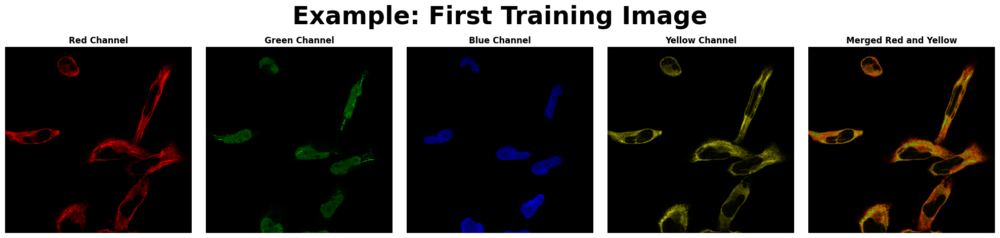

In [22]:
# Visualizing how merging red and yellow channels would look like => getting ready for Cellpose

plt.figure(figsize = (20, 6))

# Display individual channel images
for i, c in enumerate(["Red Channel", "Green Channel", "Blue Channel", "Yellow Channel"]):
    channel_image = np.zeros_like(rgby_image[..., :-1])
    if c == "Red Channel":
        channel_image[..., 0] = rgby_image[..., i]                          # i = 0
    elif c == "Green Channel":
        channel_image[..., 1] = rgby_image[..., i]                          # i = 1
    elif c == "Blue Channel":
        channel_image[..., 2] = rgby_image[..., i]                          # i = 2
    elif c == "Yellow Channel":
        channel_image[..., 0] = rgby_image[..., i]                          # i = 3
        channel_image[..., 1] = rgby_image[..., i]                          # i = 4
    plt.subplot(1, 5, i + 1)
    plt.title(f"{c}", fontweight="bold")
    plt.imshow(channel_image)
    plt.axis(False)

# Display merged red-yellow image
plt.subplot(1, 5, 5)
plt.title("Merged Red and Yellow", fontweight = "bold")
merged_image = np.zeros_like(rgby_image[..., :-1])
merged_image[..., 0] = rgby_image[..., 0] + rgby_image[..., 3]
# plt.imshow(merged_image)
# plt.subplot(1, 6, 6)
# plt.title("Merged Red and Yellow in color", fontweight = "bold")
merged_image[..., 1] = rgby_image[..., 3]
plt.imshow(merged_image)
plt.axis(False)

plt.suptitle("Example: First Training Image", fontsize = 35, fontweight = "bold")
plt.tight_layout(rect=[0, 0.2, 1, 0.97])
plt.show()


In [17]:
# # Merging red and yellow channels => getting ready for Cellpose

# import os
# from PIL import Image
# import numpy as np
# import matplotlib.pyplot as plt

# # Define the directory containing the images
# image_dir = "train/toy_data/"

# # Define the directory to save the merged images
# output_dir = "train/merged_images"
# os.makedirs(output_dir, exist_ok=True)

# # Iterate through each file in mt
# for file_path in tqdm(mt):
#     # Load the image
#     file_prefix = file_path.split('_red.png')[0]
#     rgby_image = load_image(file_prefix, image_dir) 

#     # plt.figure(figsize = (20, 6))

#     # Display individual channel images
#     for i, c in enumerate(["Red Channel", "Green Channel", "Blue Channel", "Yellow Channel"]):
#         channel_image = np.zeros_like(rgby_image[..., :-1])
#         if c == "Red Channel":
#             channel_image[..., 0] = rgby_image[..., i]                          # i = 0
#         elif c == "Green Channel":
#             channel_image[..., 1] = rgby_image[..., i]                          # i = 1
#         elif c == "Blue Channel":
#             channel_image[..., 2] = rgby_image[..., i]                          # i = 2
#         elif c == "Yellow Channel":
#             channel_image[..., 0] = rgby_image[..., i]                          # i = 3
#             channel_image[..., 1] = rgby_image[..., i]                          # i = 4
#         # plt.subplot(1, 5, i + 1)
#         # plt.title(f"{c}", fontweight="bold")
#         # plt.imshow(channel_image)
#         # plt.axis(False)

#     # # Display merged red-yellow image
#     # plt.subplot(1, 5, 5)
#     # plt.title("Merged Red and Yellow", fontweight = "bold")
#     # merged_image = np.zeros_like(rgby_image[..., :-1])
#     # Combine red and yellow channels
#     merged_image = rgby_image[..., 0] + rgby_image[..., 3]
#     # # merged_image[..., 1] = rgby_image[..., 3]                                 # for visualization purposes
#     # plt.imshow(merged_image)
#     # # plt.subplot(1, 6, 6)
#     # # plt.title("Merged Red and Yellow in color", fontweight = "bold")
#     # # merged_image[..., 1] = rgby_image[..., 3]
#     # # plt.imshow(merged_image)
#     # plt.axis(False)

#     # plt.suptitle(f"Example: {file_name}", fontweight = "bold")
#     # plt.tight_layout(rect = [0, 0.2, 1, 0.97])
#     # plt.axis('off')
#     # plt.show()

#     # Extract the file name without extension
#     file_name = os.path.splitext(os.path.basename(file_path).split('_red')[0])[0]

#     # Define the output file path for merged image
#     output_path_merged = os.path.join(output_dir, f"{file_name}_merged.png")

#     # Convert the merged image to PIL Image
#     merged_image_pil = Image.fromarray(np.uint8(merged_image))

#     # Save the merged image to the output path
#     merged_image_pil.save(output_path_merged)

#     # print(f"Merged image saved successfully: {output_path_merged}")


In [23]:
!pip install "opencv-python-headless<4.3"
!pip install cellpose


[notice] A new release of pip is available: 23.3.1 -> 24.0
[notice] To update, run: python.exe -m pip install --upgrade pip



[notice] A new release of pip is available: 23.3.1 -> 24.0
[notice] To update, run: python.exe -m pip install --upgrade pip


**Import libraries and check GPU**

In [24]:
import numpy as np
import time, os, sys
from urllib.parse import urlparse
import skimage.io
import matplotlib.pyplot as plt
import matplotlib as mpl
%matplotlib inline
mpl.rcParams['figure.dpi'] = 300

from urllib.parse import urlparse
from cellpose import models, core

use_GPU = core.use_gpu()
print('>>> GPU activated? %d'%use_GPU)

# call logger_setup to have output of cellpose written
from cellpose.io import logger_setup
logger_setup();


>>> GPU activated? 1
2024-03-02 12:05:32,252 [INFO] WRITING LOG OUTPUT TO C:\Users\szhan\.cellpose\run.log
2024-03-02 12:05:32,252 [INFO] 
cellpose version: 	3.0.5 
platform:       	win32 
python version: 	3.11.5 
torch version:  	2.3.0.dev20240122+cu121


Length of image_paths: 21806
2024-03-02 12:06:07,671 [INFO] ** TORCH CUDA version installed and working. **
2024-03-02 12:06:07,673 [INFO] >>>> using GPU
2024-03-02 12:06:07,674 [INFO] >> cyto2 << model set to be used
2024-03-02 12:06:07,840 [INFO] >>>> model diam_mean =  30.000 (ROIs rescaled to this size during training)
Length of images:  3
train/data\b853dd5e-bbc1-11e8-b2bb-ac1f6b6435d0.png
b853dd5e-bbc1-11e8-b2bb-ac1f6b6435d0.png
b853dd5e-bbc1-11e8-b2bb-ac1f6b6435d0
2024-03-02 12:06:08,351 [INFO] channels set to [0, 0]
2024-03-02 12:06:08,351 [INFO] ~~~ FINDING MASKS ~~~
2024-03-02 12:06:38,512 [INFO] >>>> TOTAL TIME 30.16 sec
2024-03-02 12:06:38,614 [INFO] channels set to [0, 0]
2024-03-02 12:06:38,625 [INFO] ~~~ FINDING MASKS ~~~
2024-03-02 12:07:01,760 [INFO] >>>> TOTAL TIME 23.15 sec
2024-03-02 12:07:01,820 [INFO] channels set to [0, 0]
2024-03-02 12:07:01,820 [INFO] ~~~ FINDING MASKS ~~~
2024-03-02 12:07:08,758 [INFO] >>>> TOTAL TIME 6.94 sec
2024-03-02 12:07:08,843 [INFO] ch

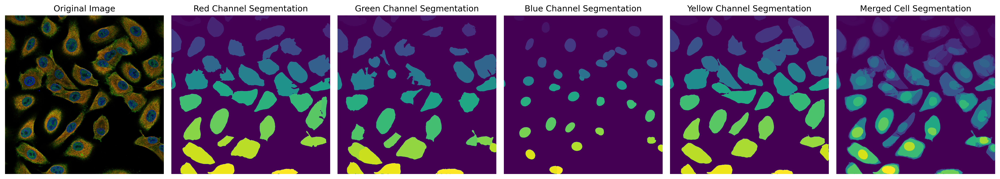

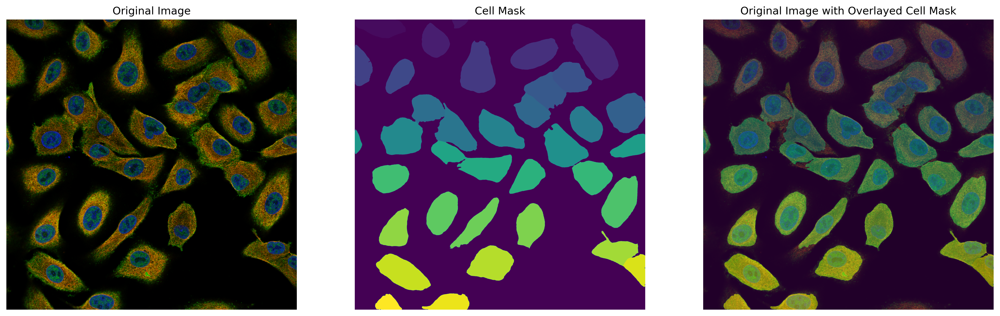

train/data\abf11b04-bbc0-11e8-b2bb-ac1f6b6435d0.png
abf11b04-bbc0-11e8-b2bb-ac1f6b6435d0.png
abf11b04-bbc0-11e8-b2bb-ac1f6b6435d0
2024-03-02 12:08:10,015 [INFO] channels set to [0, 0]
2024-03-02 12:08:10,016 [INFO] ~~~ FINDING MASKS ~~~
2024-03-02 12:08:17,866 [INFO] >>>> TOTAL TIME 7.85 sec
2024-03-02 12:08:17,913 [INFO] channels set to [0, 0]
2024-03-02 12:08:17,914 [INFO] ~~~ FINDING MASKS ~~~
2024-03-02 12:08:24,770 [INFO] >>>> TOTAL TIME 6.86 sec
2024-03-02 12:08:24,830 [INFO] channels set to [0, 0]
2024-03-02 12:08:24,833 [INFO] ~~~ FINDING MASKS ~~~
2024-03-02 12:08:30,144 [INFO] >>>> TOTAL TIME 5.31 sec
2024-03-02 12:08:30,215 [INFO] channels set to [0, 0]
2024-03-02 12:08:30,217 [INFO] ~~~ FINDING MASKS ~~~
2024-03-02 12:08:39,679 [INFO] >>>> TOTAL TIME 9.47 sec
2024-03-02 12:08:39,738 [INFO] channels set to [1, 3]
2024-03-02 12:08:39,740 [INFO] ~~~ FINDING MASKS ~~~
2024-03-02 12:08:49,362 [INFO] >>>> TOTAL TIME 9.62 sec
(2048, 2048)


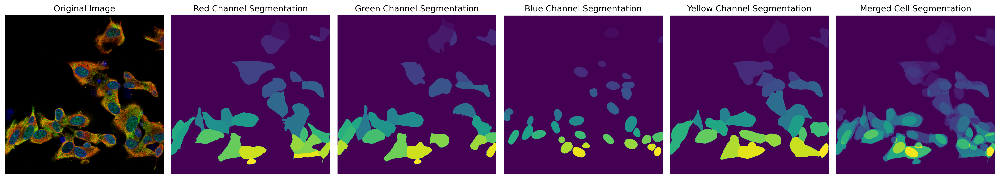

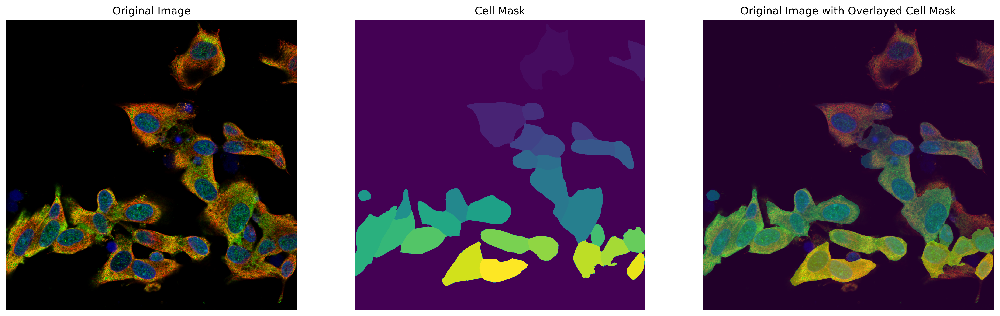

train/data\d28b876a-bb9b-11e8-b2b9-ac1f6b6435d0.png
d28b876a-bb9b-11e8-b2b9-ac1f6b6435d0.png
d28b876a-bb9b-11e8-b2b9-ac1f6b6435d0
2024-03-02 12:09:03,999 [INFO] channels set to [0, 0]
2024-03-02 12:09:04,001 [INFO] ~~~ FINDING MASKS ~~~
2024-03-02 12:09:24,600 [INFO] >>>> TOTAL TIME 20.60 sec
2024-03-02 12:09:24,742 [INFO] channels set to [0, 0]
2024-03-02 12:09:24,745 [INFO] ~~~ FINDING MASKS ~~~
2024-03-02 12:09:39,458 [INFO] >>>> TOTAL TIME 14.72 sec
2024-03-02 12:09:39,564 [INFO] channels set to [0, 0]
2024-03-02 12:09:39,566 [INFO] ~~~ FINDING MASKS ~~~
2024-03-02 12:09:51,810 [INFO] >>>> TOTAL TIME 12.25 sec
2024-03-02 12:09:51,936 [INFO] channels set to [0, 0]
2024-03-02 12:09:51,938 [INFO] ~~~ FINDING MASKS ~~~
2024-03-02 12:10:16,103 [INFO] >>>> TOTAL TIME 24.17 sec
2024-03-02 12:10:16,268 [INFO] channels set to [1, 3]
2024-03-02 12:10:16,271 [INFO] ~~~ FINDING MASKS ~~~
2024-03-02 12:10:44,911 [INFO] >>>> TOTAL TIME 28.64 sec
(3072, 3072)


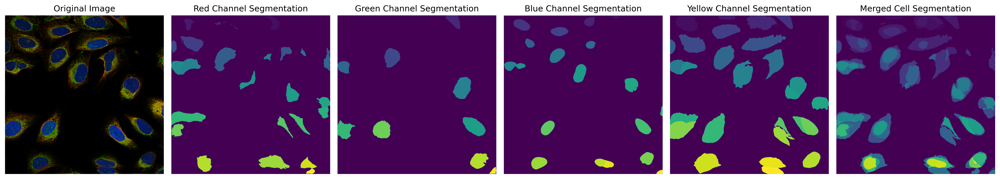

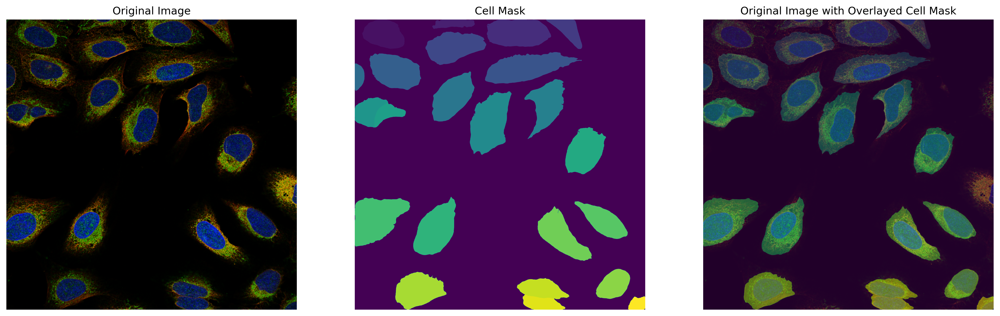

In [26]:
import os
import numpy as np
import skimage.io
from cellpose import models

# Define the directory containing the image files
# image_dir = "/project/btec-design3/kaggle_dataset/train2021"                      # SCC
image_dir = PATH_OF_DATA                                                        # Local

# List all the image files in the directory
image_paths = []

for filename in os.listdir(image_dir):
    # Check if the file has a supported image extension
    if filename.lower().endswith(('.png', '.jpg', '.jpeg')):
        # Remove the suffixes (_red, _blue, _green, _yellow) from the file name
        file_name = os.path.basename(filename)
        filename_without_suffix = os.path.splitext(file_name)[0].rsplit('_', 1)[0]
        # print(file_name_without_suffix)
        # Construct the full path to the image file
        image_path = os.path.join(image_dir, filename_without_suffix + os.path.splitext(file_name)[1])
        # Append the image path to the list
        image_paths.append(image_path)
        # print('Length of image_paths so far: ', len(image_paths))

# Use set() to remove duplicate paths, if any
image_paths = set(image_paths)

print("Length of image_paths:", len(image_paths))


device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# Initialize Cellpose model for cell segmentation
model = models.Cellpose(gpu = True, model_type = 'cyto2',  device = device)

diameter = 150

images = list(image_paths)[:3]

print('Length of images: ', len(images))

# Function to segment cells for each image
def segment_cells(images):
    
    # Segment cells using Cellpose for each channel
    masks = []
    for channel in ["red", "green", "blue", "yellow"]:
        # Load the specific channel image
        
        channel_image_path = images.replace(".png", f"_{channel}.png")
        channel_image = skimage.io.imread(channel_image_path)
        
        # Segment cells using Cellpose
        masks_chan, _, _, _ = model.eval(channel_image, diameter = diameter, channels = [0, 0])
        masks.append(masks_chan)
    
    # Merge masks from different channels
    merged_mask = np.sum(masks, axis = 0)
    
    return masks, merged_mask

# Segment cells for each image and merge the masks
for image_path in images:

    print(image_path)

    #file_path = os.path.splitext(image_path)[0].rsplit('_', 2)
    #print(file_path)
    # print(image_path)
    file_name = os.path.basename(image_path)
    print(file_name)
    file_name = os.path.splitext(file_name)[0].rsplit('_', 1)[0]
    print(file_name)
    original_image = load_image(file_name, PATH_OF_DATA)
    original_image = rgby_to_rgb(original_image)

    # print(image_path)
    cell_masks, merged_mask = segment_cells(image_path)

    masking, _, _, _ = model.eval(original_image, diameter = diameter, channels = [1, 3])

    # Display the merged cell segmentation
    fig, axes = plt.subplots(1, 6, figsize = (20, 10))
    axes[0].imshow(original_image)
    axes[0].set_title('Original Image')
    axes[0].axis('off')
    # axes[0].axis('off')
    for i, (channel, mask) in enumerate(zip(["Red", "Green", "Blue", "Yellow"], cell_masks)):
        axes[i + 1].imshow(mask)
        axes[i + 1].set_title(f'{channel} Channel Segmentation')

    axes[-1].imshow(merged_mask)
    print(merged_mask.shape)
    axes[-1].set_title('Merged Cell Segmentation')

    for ax in axes[:6]:
        ax.axis('off')
    
    plt.tight_layout()
    plt.show()

    fig, axes = plt.subplots(1, 3, figsize = (20, 10))
    axes[0].imshow(original_image)
    axes[0].set_title('Original Image')
    axes[0].axis('off')
    axes[1].imshow(masking)
    axes[1].set_title('Cell Mask')
    axes[1].axis('off')
    axes[2].imshow(original_image)
    axes[2].set_title('Original Image with Overlayed Cell Mask')
    axes[2].imshow(masking, alpha = 0.5)
    axes[2].axis('off')
    plt.show()

# So it seems that segmenting using nuclei on the red + yellow channel is better approach than segmenting 4 channels individually and then overlaying on top of each other . . . 


Length of image_paths: 21806
2024-03-03 12:36:53,484 [INFO] ** TORCH CUDA version installed and working. **
2024-03-03 12:36:53,485 [INFO] >>>> using GPU
2024-03-03 12:36:53,486 [INFO] >> cyto2 << model set to be used
2024-03-03 12:36:53,703 [INFO] >>>> model diam_mean =  30.000 (ROIs rescaled to this size during training)
Length of images:  1
b853dd5e-bbc1-11e8-b2bb-ac1f6b6435d0.png
b853dd5e-bbc1-11e8-b2bb-ac1f6b6435d0
2024-03-03 12:36:54,359 [INFO] channels set to [0, 0]
2024-03-03 12:36:54,360 [INFO] ~~~ FINDING MASKS ~~~
2024-03-03 12:37:19,252 [INFO] >>>> TOTAL TIME 24.89 sec
2024-03-03 12:37:19,352 [INFO] channels set to [0, 0]
2024-03-03 12:37:19,353 [INFO] ~~~ FINDING MASKS ~~~
2024-03-03 12:37:41,846 [INFO] >>>> TOTAL TIME 22.49 sec
2024-03-03 12:37:41,913 [INFO] channels set to [0, 0]
2024-03-03 12:37:41,914 [INFO] ~~~ FINDING MASKS ~~~
2024-03-03 12:37:49,400 [INFO] >>>> TOTAL TIME 7.49 sec
2024-03-03 12:37:49,489 [INFO] channels set to [0, 0]
2024-03-03 12:37:49,490 [INFO] 

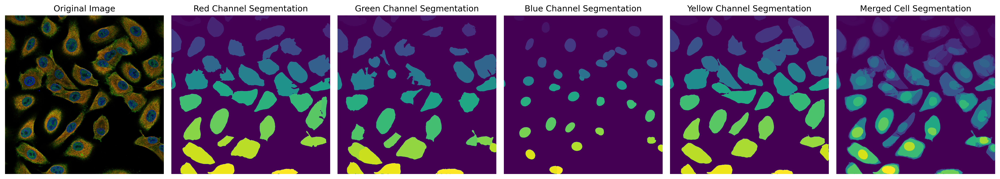

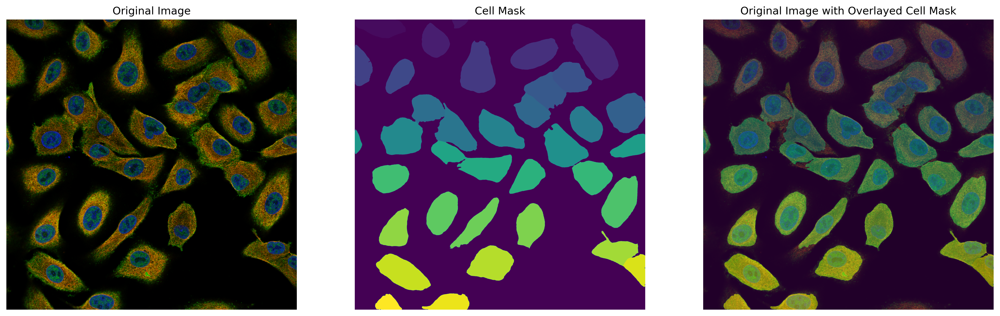

Number of Unique Masks:  [ 1  2  3  4  5  6  7  8  9 10 11 12 13 14 15 16 17 18 19 20 21 22 23 24
 25 26 27 28 29 30 31 32 33 34 35 36]
Number of Cells:  36
Number of rows:  9
Number of columns:  4


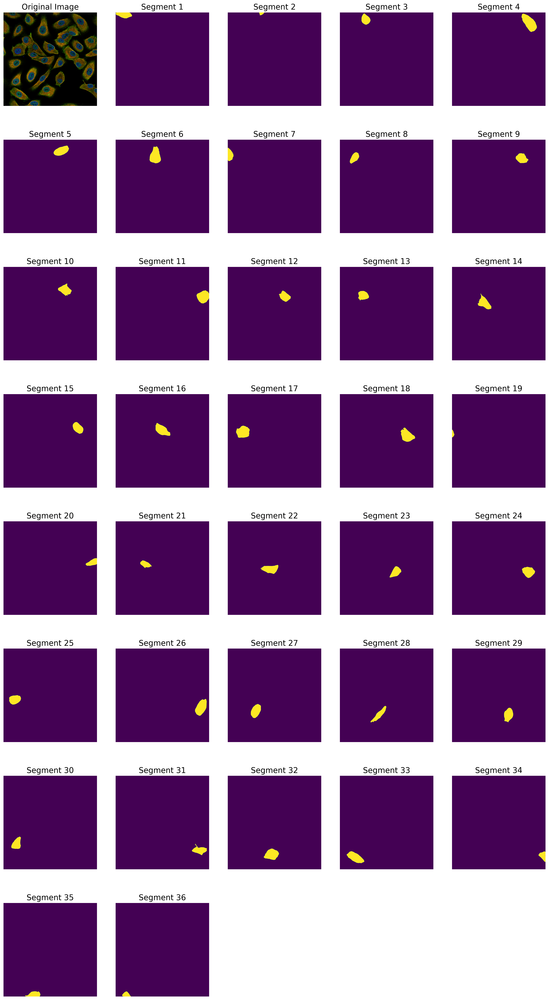

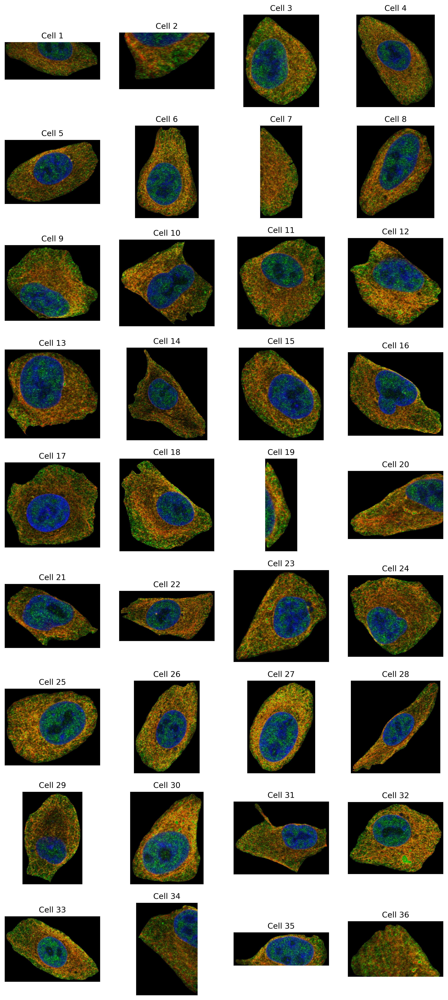

In [182]:
import os
import numpy as np
import skimage.io
from cellpose import models, utils

# Define the directory containing the image files
# image_dir = "/project/btec-design3/kaggle_dataset/train2021"                      # SCC
image_dir = PATH_OF_DATA                                                         # Local                 

# List all the image files in the directory
image_paths = []

for filename in os.listdir(image_dir):
    # Check if the file has a supported image extension
    if filename.lower().endswith(('.png', '.jpg', '.jpeg')):
        # Remove the suffixes (_red, _blue, _green, _yellow) from the file name
        file_name = os.path.basename(filename)
        filename_without_suffix = os.path.splitext(file_name)[0].rsplit('_', 1)[0]
        # print(file_name_without_suffix)
        # Construct the full path to the image file
        image_path = os.path.join(image_dir, filename_without_suffix + os.path.splitext(file_name)[1])
        # Append the image path to the list
        image_paths.append(image_path)
        # print('Length of image_paths so far: ', len(image_paths))

# Use set() to remove duplicate paths, if any
image_paths = set(image_paths)

print("Length of image_paths:", len(image_paths))


device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# Initialize Cellpose model for cell segmentation
model = models.Cellpose(gpu = True, model_type = 'cyto2',  device = device)         # model_type = 'cyto2' because 'cyto' is the original Cellpose model and 'cyto2' is trained on the 'cyto' dataset plus user-submitted data so it may be more refined

diameter = 150

images = list(image_paths)[:1]

print('Length of images: ', len(images))

def extract_individual_cells(masking):
    # print(masking)
    unique_masks = np.unique(masking)
    # print(unique_masks)

    unique_masks = unique_masks[unique_masks != 0]
    # print(unique_masks)

    index = 0
    index += 1
    individual_cells = []

    for number in unique_masks:
        isolated_cell = np.where(masking == number, masking, 0)

        index += 1
    
        individual_cells.append(isolated_cell)

    return individual_cells

# Function to segment cells for each image
def segment_cells(images):
    
    # Segment cells using Cellpose for each channel
    masks = []
    for channel in ["red", "green", "blue", "yellow"]:
        # Load the specific channel image
        
        channel_image_path = images.replace(".png", f"_{channel}.png")
        channel_image = skimage.io.imread(channel_image_path)
        
        # Segment cells using Cellpose
        masks_chan, _, _, _ = model.eval(channel_image, diameter = diameter, channels = [0, 0])
        masks.append(masks_chan)
    
    # Merge masks from different channels
    merged_mask = np.sum(masks, axis = 0)
    
    return masks, merged_mask

def extract_segmented_cells(original_image, segmentation_mask):
    # Convert the segmentation mask to a binary mask (0 or 255)
    binary_mask = (segmentation_mask > 0).astype(np.uint8)

    num_cells = len(binary_mask)
    # Create subplots
    num_labels = np.max(segmentation_mask)
    num_cols = min(num_labels, 4)
    print("Number of Cells: ", num_labels)
    num_rows = (num_labels + 3) // 4
    print("Number of rows: ", num_rows)
    print("Number of columns: ", num_cols)
    plt.figure(figsize = (num_cols * 3, num_rows * 3))

    # Iterate over each label in the segmentation mask
    for label in range(1, num_labels + 1):
        # Create a mask for the current cell
        cell_mask = (segmentation_mask == label).astype(np.uint8)

        # Apply the cell mask on the original image to extract the cell
        segmented_cell = cv2.bitwise_and(original_image, original_image, mask=cell_mask)

        # Get the bounding box of the cell
        x, y, w, h = cv2.boundingRect(cell_mask)

        x -= 10
        y -= 10
        w += 20
        h += 20

        # Ensure the bounding box is within the image boundaries
        x = max(x, 0)
        y = max(y, 0)
        w = min(w, original_image.shape[1] - x)
        h = min(h, original_image.shape[0] - y)

        # Crop the cell from the resulting image
        cropped_cell = segmented_cell[y:y+h, x:x+w]

        # Plot the cell in the subplot
        plt.subplot(num_rows, num_cols, label)
        plt.imshow(cropped_cell)
        plt.axis('off')
        plt.title(f"Cell {label}")

    plt.show()

# Segment cells for each image and merge the masks
for image_path in images:

    # print(image_path)

    #file_path = os.path.splitext(image_path)[0].rsplit('_', 2)
    #print(file_path)
    # print(image_path)
    file_name = os.path.basename(image_path)
    print(file_name)
    file_name = os.path.splitext(file_name)[0].rsplit('_', 1)[0]
    print(file_name)
    original_image = load_image(file_name, PATH_OF_DATA)
    original_image = rgby_to_rgb(original_image)

    # print(image_path)
    cell_masks, merged_mask = segment_cells(image_path)

    masking, _, _, _ = model.eval(original_image, diameter = diameter, channels = [1, 3])

    # Display the merged cell segmentation
    fig, axes = plt.subplots(1, 6, figsize = (20, 10))
    axes[0].imshow(original_image)
    axes[0].set_title('Original Image')
    axes[0].axis('off')
    # axes[0].axis('off')
    for i, (channel, mask) in enumerate(zip(["Red", "Green", "Blue", "Yellow"], cell_masks)):
        axes[i + 1].imshow(mask)
        axes[i + 1].set_title(f'{channel} Channel Segmentation')
        if channel == "Blue":
            nucleus_mask = mask

    axes[-1].imshow(merged_mask)
    print(merged_mask.shape)
    axes[-1].set_title('Merged Cell Segmentation')

    for ax in axes[:6]:
        ax.axis('off')
    
    plt.tight_layout()
    plt.show()

    fig, axes = plt.subplots(1, 3, figsize = (20, 10))
    axes[0].imshow(original_image)
    axes[0].set_title('Original Image')
    axes[0].axis('off')
    axes[1].imshow(masking)
    axes[1].set_title('Cell Mask')
    axes[1].axis('off')
    axes[2].imshow(original_image)
    axes[2].set_title('Original Image with Overlayed Cell Mask')
    axes[2].imshow(masking, alpha = 0.5)
    axes[2].axis('off')
    plt.show()

    individual_cells = extract_individual_cells(masking)
    unique_masks = np.unique(masking)
    fig = plt.figure(figsize = (20, len(unique_masks)))
    unique_masks = unique_masks[unique_masks != 0]
    print("Number of Unique Masks: ", unique_masks)

    # Create a subplot for the original image
    ax0 = fig.add_subplot(len(unique_masks)//5+1, 5, 1)
    ax0.imshow(original_image)
    ax0.set_title("Original Image", size = 16)
    ax0.axis('off')

    # Iterate through each individual cell segment
    for i, cell_segment in enumerate(individual_cells):
        # print(i)
        # Process each individual cell segment as needed
        ax = fig.add_subplot(len(unique_masks)//5+1, 5, i + 2)
        ax.set_title(f"Segment {i + 1}", size = 16)
        # plt.imshow(isolated_cell)
        plt.imshow(cell_segment)
        ax.axis('off')

    extract_segmented_cells(original_image, masking)
# So it seems that segmenting using nuclei on the red + yellow channel is better approach than segmenting 4 channels individually and then overlaying on top of each other . . . 


<div class = "alert alert-block alert-info"> <b>Note: </b> 

So it seems that segmenting using nuclei on the red + yellow channel performs pretty well . . . but there are some discrepancies in the cell mask => ex. in the first image, Segment 7 only covers ~half the cell . . . so what if used the nuclei segmentation to help make the cell mask more accurate . . . 

additionally, based on previous results from other teams, it appears that cells at the boundaries are very likely to be classified wrong and did not perform well . . . so perhaps we can exclude the cell masks that are for cells at the boundaries (determined by whether nucleus is touching the boundary)
           
</div> 

In [288]:
# import cv2
# import numpy as np
# import matplotlib.pyplot as plt

# def extract_segmented_cells(original_image, segmentation_mask, nucleus_mask):
#     # Convert the segmentation mask to a binary mask (0 or 255)
#     binary_mask = (segmentation_mask > 0).astype(np.uint8)

#     num_cells = len(binary_mask)
#     # Create subplots
#     num_labels = np.max(segmentation_mask)
#     num_cols = min(num_labels, 4)
#     print("Number of Cells: ", num_labels)
#     num_rows = (num_labels + 3) // 4
#     print("Number of rows: ", num_rows)
#     print("Number of columns: ", num_cols)
#     # plt.figure(figsize = (num_cols * 3, num_rows * 3))

#     # Get the dimensions of the image
#     height, width = original_image.shape[:2]

#     print('Number of Nucleus: ', np.max(nucleus_mask))
#     # Iterate over each label in the segmentation mask
#     for label in range(1, np.max(nucleus_mask) + 1):
#         # Create a mask for the current cell
#         # cell_mask = (segmentation_mask == label).astype(np.uint8)
#         nucleus = (nucleus_mask == label).astype(np.uint8)

#         # Check if the nucleus touches the boundary of the image
#         nucleus_pixels = np.argwhere(nucleus_mask == label)
#         if (np.any(nucleus_pixels[:, 0] == 0) or
#             np.any(nucleus_pixels[:, 0] == height - 5) or
#             np.any(nucleus_pixels[:, 1] == 0) or
#             np.any(nucleus_pixels[:, 1] == width - 5)):
#             print("Cell", label, "touches the boundary")
#             continue  # Skip this cell if the nucleus touches the boundary

#         # # Find the cell mask that fully encloses the nucleus
#         # cell_mask = binary_mask * nucleus
#         # if not np.any(cell_mask):
#         #     print("No enclosing cell found for nucleus", label)
#         #     continue

#         # Find the cell mask that fully encloses the nucleus
#         for cell_label in range(1, np.max(segmentation_mask) + 1):
#             cell_mask = (segmentation_mask == cell_label).astype(np.uint8)
#             if np.any(cell_mask & nucleus):
#                 enclosing_cell_index = cell_label
#                 print(enclosing_cell_index)
#                 break
#         else:
#             print("No enclosing cell found for nucleus", label)
#             continue
        
#         # Apply the cell mask on the original image to extract the cell
#         cell_seg = original_image.copy()
#         cell_seg[segmentation_mask != enclosing_cell_index] = 0

        
#         # Get the bounding box of the cell
#         x, y, w, h = cv2.boundingRect(cell_mask)

#         x -= 20
#         y -= 20
#         w += 40
#         h += 40

#         # Ensure the bounding box is within the image boundaries
#         x = max(x, 0)
#         y = max(y, 0)
#         w = min(w, original_image.shape[1] - x)
#         h = min(h, original_image.shape[0] - y)

#         # Crop the cell from the resulting image
#         cropped_cell = cell_seg[y:y+h, x:x+w]

#         # Plot the cell in the subplot
#         plt.subplot(num_rows, num_cols, label)
#         plt.imshow(cropped_cell)
#         plt.axis('off')
#         plt.title(f"Cell {label}", size = 10)

#     plt.show()

# # Example usage:
# # extract_segmented_cells(original_image, segmentation_mask, nucleus_mask)


import cv2
import numpy as np
import matplotlib.pyplot as plt

def extract_segmented_cells(original_image, segmentation_mask, nucleus_mask):
    # Convert the segmentation mask to a binary mask (0 or 255)
    binary_mask = (segmentation_mask > 0).astype(np.uint8)

    # Get the dimensions of the image
    height, width = original_image.shape[:2]

    # Create subplots
    num_labels = np.max(nucleus_mask)
    num_cols = min(num_labels, 4)
    num_rows = (num_labels + 3) // 4

    # Initialize a subplot counter
    subplot_count = 1

    # Iterate over each nucleus
    for label in range(1, np.max(nucleus_mask) + 1):
        nucleus = (nucleus_mask == label).astype(np.uint8)

        # Check if the nucleus touches the boundary of the image
        nucleus_pixels = np.argwhere(nucleus_mask == label)
        if (np.any(nucleus_pixels[:, 0] == 0) or
            np.any(nucleus_pixels[:, 0] == height - 5) or
            np.any(nucleus_pixels[:, 1] == 0) or
            np.any(nucleus_pixels[:, 1] == width - 5)):
            print("Nucleus", label, "touches the boundary")
            continue  # Skip this nucleus if it touches the boundary

        # Initialize variables to store the largest cell mask
        max_area = 0
        max_cell_mask = None

        # Iterate over each cell mask to find the largest one that fully encloses the nucleus
        for cell_label in range(1, np.max(segmentation_mask) + 1):
            cell_mask = (segmentation_mask == cell_label).astype(np.uint8)
            if np.any(cell_mask & nucleus):
                # Calculate the area of the intersection between the cell mask and the nucleus
                area = np.sum(cell_mask & nucleus)

                # Check if this cell mask is larger than the previous ones
                if area > max_area:
                    max_area = area
                    max_cell_mask = cell_mask

        # Check if a valid cell mask was found
        if max_cell_mask is not None:
            # Apply the cell mask on the original image to extract the cell
            cell_seg = cv2.bitwise_and(original_image, original_image, mask=max_cell_mask)

            # Get the bounding box of the cell
            x, y, w, h = cv2.boundingRect(max_cell_mask)

            # Add padding to the bounding box
            x -= 20
            y -= 20
            w += 40
            h += 40

            # Ensure the bounding box is within the image boundaries
            x = max(x, 0)
            y = max(y, 0)
            w = min(w, original_image.shape[1] - x)
            h = min(h, original_image.shape[0] - y)

            # Crop the cell from the resulting image
            cropped_cell = cell_seg[y:y + h, x:x + w]

            # Plot the cell in the subplot
            plt.subplot(num_rows, num_cols, subplot_count)
            plt.imshow(cropped_cell)
            plt.axis('off')
            plt.title(f"Cell {label}", size=10)

            # Increment the subplot counter
            subplot_count += 1
        else:
            print("No enclosing cell found for nucleus", label)

    plt.tight_layout()
    plt.show()

# Example usage:
# extract_segmented_cells(original_image, segmentation_mask, nucleus_mask)


Number of Unique Masks:  [ 1  2  3  4  5  6  7  8  9 10 11 12 13 14 15 16 17 18 19 20 21 22 23 24
 25 26 27 28 29 30 31 32 33 34 35]


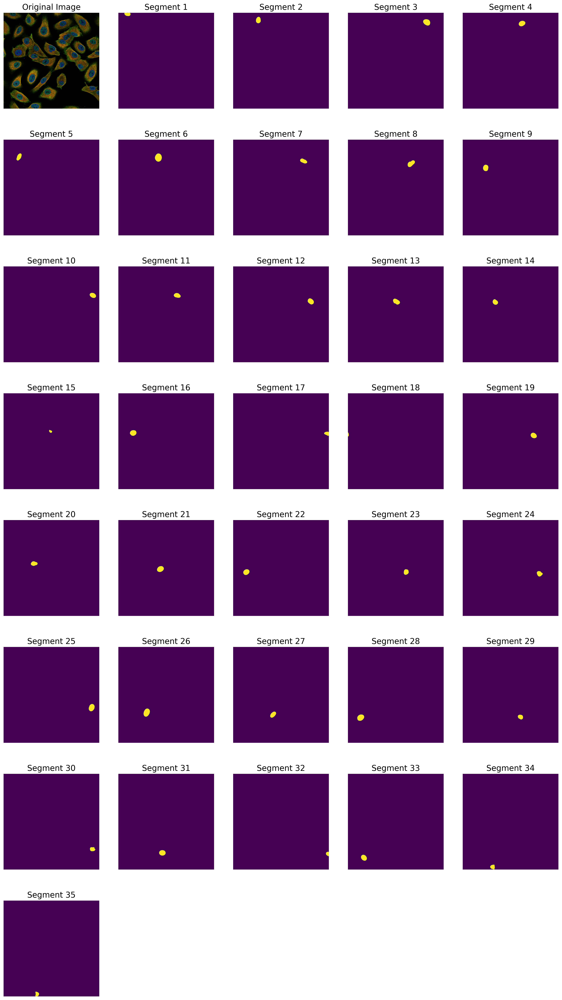

Nucleus 1 touches the boundary
Nucleus 17 touches the boundary
Nucleus 18 touches the boundary
Nucleus 32 touches the boundary
Nucleus 34 touches the boundary
Nucleus 35 touches the boundary


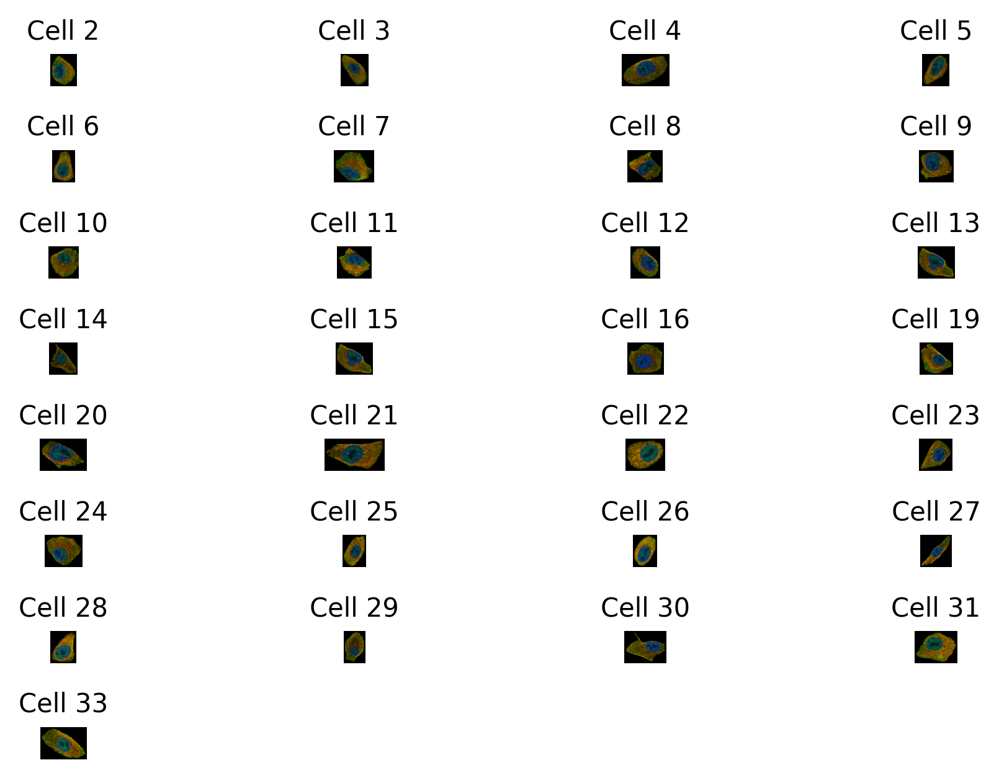

In [289]:
individual_cells = extract_individual_cells(nucleus_mask)
unique_masks = np.unique(nucleus_mask)
fig = plt.figure(figsize = (20, len(unique_masks)))
unique_masks = unique_masks[unique_masks != 0]
print("Number of Unique Masks: ", unique_masks)

# Create a subplot for the original image
ax0 = fig.add_subplot(len(unique_masks)//5+1, 5, 1)
ax0.imshow(original_image)    
ax0.set_title("Original Image", size = 16)
ax0.axis('off')

# Iterate through each individual cell segment
for i, cell_segment in enumerate(individual_cells):
    # print(i)
    # Process each individual cell segment as needed
    ax = fig.add_subplot(len(unique_masks)//5+1, 5, i + 2)
    ax.set_title(f"Segment {i + 1}", size = 16)
    # plt.imshow(isolated_cell)
    plt.imshow(cell_segment)
    ax.axis('off')
plt.show()

extract_segmented_cells(original_image, masking, nucleus_mask)

In [30]:
# Load the training CSV
train_df = pd.read_csv("train/train.csv")
train_df.head()

# Dataframe column names
ID = "ID"
IMAGE_HEIGHT = "ImageHeight"
IMAGE_WIDTH = "ImageWidth"
IMAGE_SHAPE = "ImageShape"
LABEL = "Label"

# Split on '|'
labels = train_df[LABEL].str.split("|")
labels.head()

# One hot encode the labels
has_label = lambda label_list, label_num: 1.0 if str(label_num) in label_list else 0.0

label_truth = {label_num: labels.apply(has_label, label_num=label_num)
               for label_num in range(len(all_locations))}

label_truth[ID] = train_df[ID]
label_truth[ID].head()

train_truth = pd.DataFrame(label_truth).set_index(ID)
train_truth.head()


,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18
ID,,,,,,,,,,,,,,,,,,,
5c27f04c-bb99-11e8-b2b9-ac1f6b6435d0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
5fb643ee-bb99-11e8-b2b9-ac1f6b6435d0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0
60b57878-bb99-11e8-b2b9-ac1f6b6435d0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
5c1a898e-bb99-11e8-b2b9-ac1f6b6435d0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0
5b931256-bb99-11e8-b2b9-ac1f6b6435d0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0


In [32]:
from typing import Optional, Tuple, List, Any
import PIL

# Dataset channel names
PROTEIN_OF_INTEREST = "green"
NUCLEUS = "blue"
MICROTUBULE = "red"
ENDOPLASMIC_RETICULUM = "yellow"

CHANNEL_NAMES = {
    PROTEIN_OF_INTEREST: "Protein of Interest", 
    NUCLEUS: "Nucleus", 
    MICROTUBULE: "Microtubule",
    ENDOPLASMIC_RETICULUM: "Endoplasmic Reticulum",
}

# Function that computes the image height and width for all images in a folder
def read_image_dimensions(
    folder_path: str, 
    file_ext: str = ".png",
    id: str = ID, 
    height: str = IMAGE_HEIGHT, 
    width: str = IMAGE_WIDTH,
    shape: str = IMAGE_SHAPE,
    channel: str = PROTEIN_OF_INTEREST,
    file_slice: slice = slice(None),
) -> pd.DataFrame:
    """
    Reads the image height and width for all files in the folder path
    that end in with the string specified in channel.
    
    Args:
        folder_path: The path to the folder containing the image files.
        file_ext: The file extension that we are interested in.
        id: The column name for the file id. The file id is acquired from
            the filename which is assumed to be in the format 
            <id>_<channel>.ext.
        height: The column name for the image height.
        width: The column name for the image width.
        shape: The column name for the image shape.
        channel: The channel image to use for sizing (see id).
        slice: Slice to apply to the file list (used for testing).
        
    Returns:
        Dataframe consisting of columns {id}, {width}. {height} and {[channel_path]} indexed
        by {id}.
    """
    # Get all the file paths that match the channel
    file_filter = os.path.join(folder_path, f"*_{channel}{file_ext}")
    file_paths = glob.glob(file_filter)[file_slice]
    
    image_size: Tuple[int, int] = lambda file_path: PIL.Image.open(file_path).size
    def file_id(file_path: str) -> str:
        _, file_name = os.path.split(file_path)
        file_name, _ = os.path.splitext(file_name)
        id, _ = file_name.split("_")
        return id

    ids = [file_id(file_path) for file_path in file_paths]
    widths_and_heights = [image_size(file_path) for file_path in tqdm(file_paths)]
    
    df_dict = {
        id: ids,
        width: [image_width for image_width, _ in widths_and_heights],
        height: [image_height for _, image_height in widths_and_heights],
        shape: [f"W{image_width}xH{image_height}" 
                for image_width, image_height in widths_and_heights]
    }

    return pd.DataFrame(df_dict).set_index(id)

In [40]:
train_path = PATH_OF_DATA
train_image_sizes = read_image_dimensions(train_path)
train_image_sizes.head()















100%|██████████| 21806/21806 [00:01<00:00, 14905.36it/s]


,ImageWidth,ImageHeight,ImageShape
ID,,,
000a6c98-bb9b-11e8-b2b9-ac1f6b6435d0,2048,2048,W2048xH2048
000a9596-bbc4-11e8-b2bc-ac1f6b6435d0,2048,2048,W2048xH2048
000c99ba-bba4-11e8-b2b9-ac1f6b6435d0,2048,2048,W2048xH2048
001838f8-bbca-11e8-b2bc-ac1f6b6435d0,2048,2048,W2048xH2048
0020af02-bbba-11e8-b2ba-ac1f6b6435d0,2048,2048,W2048xH2048


In [39]:
train = pd.concat([train_image_sizes, train_image_sizes], axis="columns")
train


,0,1,2,3,4,5,6,7,8,9,...,12,13,14,15,16,17,18,ImageWidth,ImageHeight,ImageShape
ID,,,,,,,,,,,,,,,,,,,,,
5c27f04c-bb99-11e8-b2b9-ac1f6b6435d0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,2048,2048,W2048xH2048
5fb643ee-bb99-11e8-b2b9-ac1f6b6435d0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,1.0,0.0,0.0,0.0,0.0,2048,2048,W2048xH2048
60b57878-bb99-11e8-b2b9-ac1f6b6435d0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,3072,3072,W3072xH3072
5c1a898e-bb99-11e8-b2b9-ac1f6b6435d0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,1.0,0.0,0.0,2048,2048,W2048xH2048
5b931256-bb99-11e8-b2b9-ac1f6b6435d0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,1.0,0.0,0.0,0.0,0.0,2048,2048,W2048xH2048
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
dd0989c4-bbca-11e8-b2bc-ac1f6b6435d0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,1.0,0.0,0.0,0.0,0.0,2048,2048,W2048xH2048
dd1f7fb8-bbca-11e8-b2bc-ac1f6b6435d0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,2048,2048,W2048xH2048
dd5cb36a-bbca-11e8-b2bc-ac1f6b6435d0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,1.0,0.0,0.0,0.0,0.0,2048,2048,W2048xH2048


In [41]:
import torchvision.transforms.functional as TF

class RescaleImage(object):
    """
    Transform callable class that can be used to transform the tensor size by a
    scale value. Under the hood it uses the torchvision.functional.resize transform
    to do the work.
    """
    
    def __init__(self, scale:int = 0.25, interpolation:int = PIL.Image.BILINEAR):
        """
        This initailises the transform function.
        
        Args:
            scale: The scale factor for the image W and H dimensions (E.g. 0.5 will
                reduce the image dimensions by 50% in W and H)
            interpolation: The interpolation technique to use for the rescaling.
        """
        self._scale = scale
        self._interpolation = interpolation
        
    def __call__(self, t:torch.Tensor) -> torch.Tensor:
        """
        This is the transforming function. It takes as input a tensor or shape
        [..., H, W] and returns a tensor of the same shape but with dimensions H and
        W scaled as set in the initialiser.
        
        Args:
            t: Input tensor of shape [..., H, W]
            
        Returns:
            Tensor of shape [..., H, W] with scaled dimensions
        """
        shape_in = t.size()
        height, width = list(shape_in)[-2:]
        new_size = [int(height * self._scale), int(width * self._scale)]
        t_out = TF.resize(
            img = t, size = new_size, interpolation = self._interpolation
        )
        return t_out

In [72]:
LABELS = [
    "Nucleoplasm",
    "Nuclear membrane",
    "Nucleoli",
    "Nucleoli fibrillar center",
    "Nuclear speckles",
    "Nuclear bodies",
    "Endoplasmic reticulum",
    "Golgi apparatus",
    "Intermediate filaments",
    "Actin filaments",
    "Microtubules",
    "Mitotic spindle",
    "Centrosome",
    "Plasma membrane",
    "Mitochondria",
    "Aggresome",
    "Cytosol",
    "Vesicles and punctate cytosolic patterns",
    "Negative",
]

**Setting Up the DataLoader**

In [90]:
from cellpose import io as cellpose_io

target_cols = list(range(len(all_locations)))

# train_dataset = CellImageDataset(
#     images = train,
#     root_dir = train_path,
#     target_cols = target_cols,
#     transform = RescaleImage()
# )


# building dataset by label
train_datasets = {
    label: CellImageDataset(
        images = train[train[label]==1.0],
        root_dir = train_path,
        target_cols = target_cols,
        transform = RescaleImage()
    )
    for label in target_cols
}
train_datasets

cell_image, protein_image, labels = next(iter(train_datasets[0]))
cell_image.size()

torch.Size([3, 512, 512])

In [91]:
train_datasets = {
    label: CellImageDataset(
        images = train[train[label]==1.0],
        root_dir = train_path,
        target_cols = target_cols,
        transform = RescaleImage()
    )
    for label in target_cols
}
train_datasets

{0: <__main__.CellImageDataset at 0x27e8a1acb50>,
 1: <__main__.CellImageDataset at 0x27ea54dd8d0>,
 2: <__main__.CellImageDataset at 0x27f7d07b810>,
 3: <__main__.CellImageDataset at 0x27ea54814d0>,
 4: <__main__.CellImageDataset at 0x27ea54835d0>,
 5: <__main__.CellImageDataset at 0x27ea5481610>,
 6: <__main__.CellImageDataset at 0x27ea5482f90>,
 7: <__main__.CellImageDataset at 0x27ea54831d0>,
 8: <__main__.CellImageDataset at 0x27ea5483710>,
 9: <__main__.CellImageDataset at 0x27ea5482550>,
 10: <__main__.CellImageDataset at 0x27ea5485710>,
 11: <__main__.CellImageDataset at 0x27ea54842d0>,
 12: <__main__.CellImageDataset at 0x27ea5484e50>,
 13: <__main__.CellImageDataset at 0x27ea5485810>,
 14: <__main__.CellImageDataset at 0x27ea5484b10>,
 15: <__main__.CellImageDataset at 0x27ea54857d0>,
 16: <__main__.CellImageDataset at 0x27ea54a6ed0>,
 17: <__main__.CellImageDataset at 0x27ea54a4f10>,
 18: <__main__.CellImageDataset at 0x27ea54a4ad0>}

In [93]:
plot_images = {label: next(iter(train_datasets[label]))
               for label in tqdm(target_cols)
               if len(train_datasets[label])>0}

make_im = lambda t: t.detach().cpu().numpy().transpose((1, 2, 0))

cell_images = {label: make_im(image)
               for label, (image, _, _) in plot_images.items()}
protein_images = {label: make_im(image)
                  for label, (_, image, _) in plot_images.items()}

100%|██████████| 19/19 [00:04<00:00,  4.21it/s]


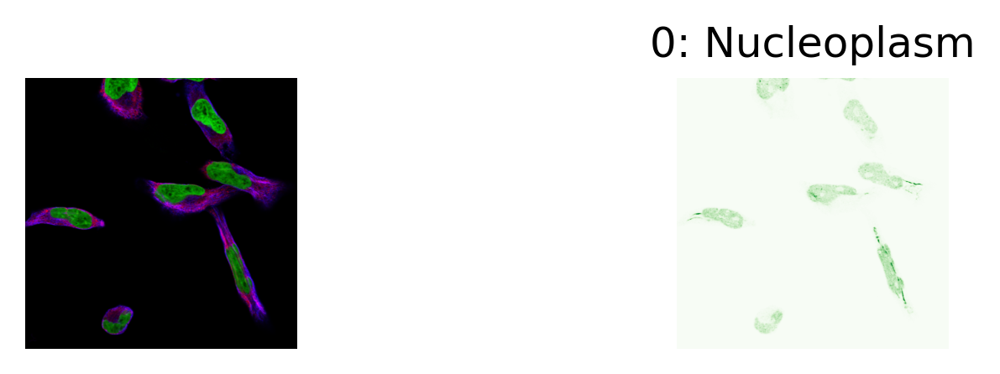

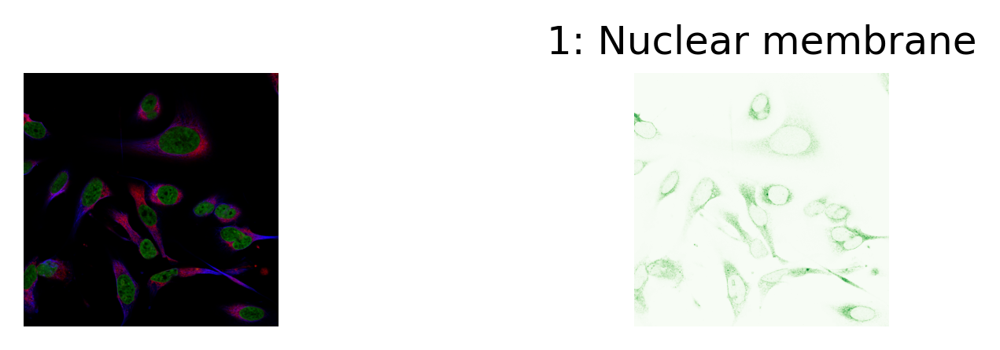

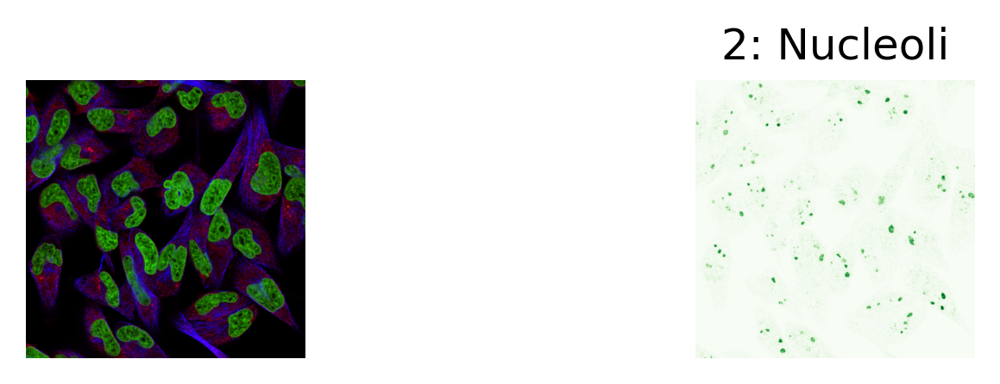

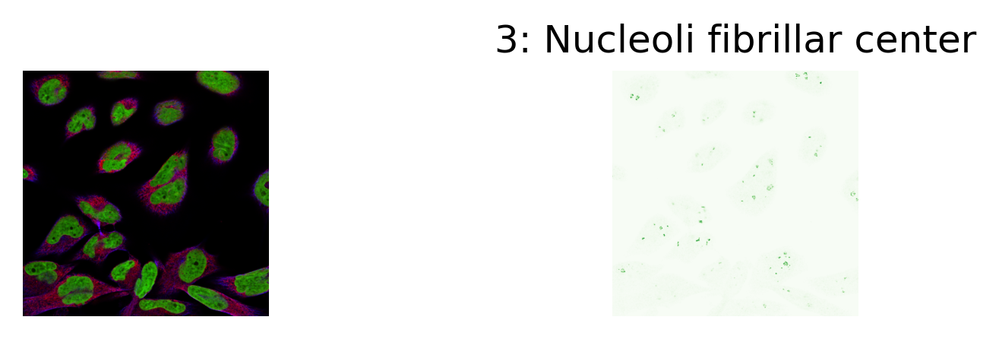

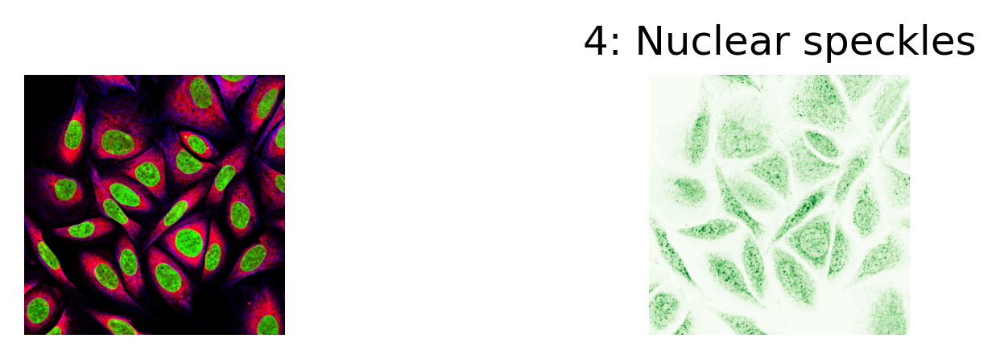

...

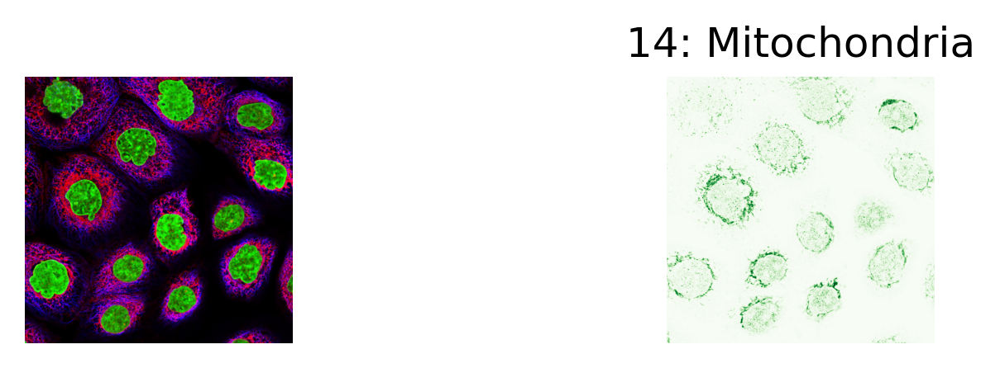

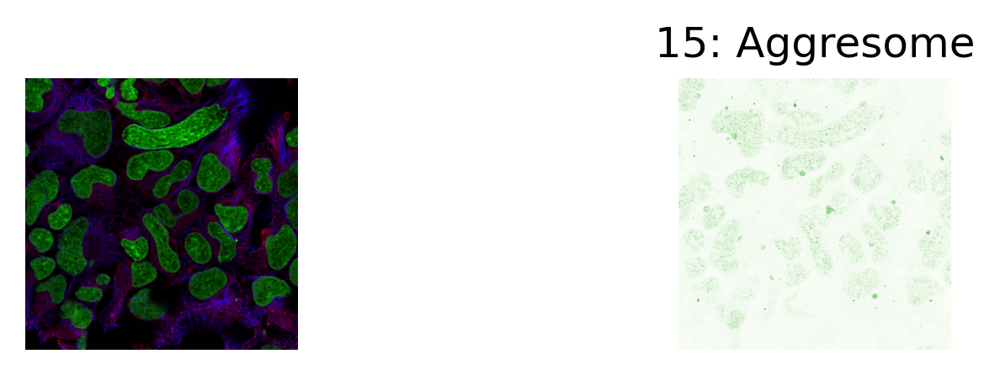

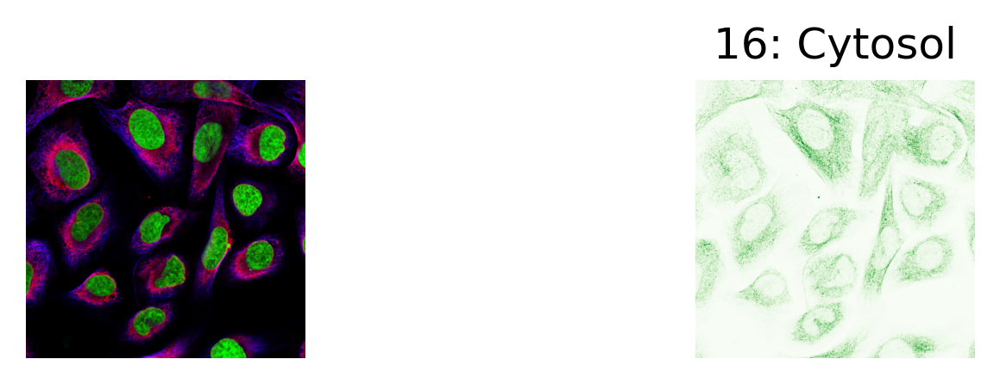

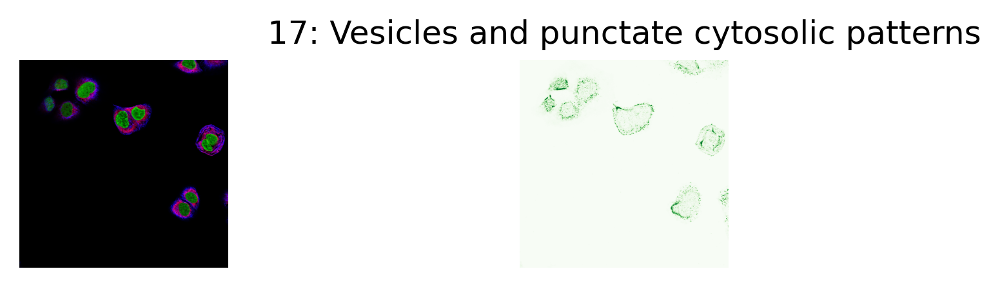

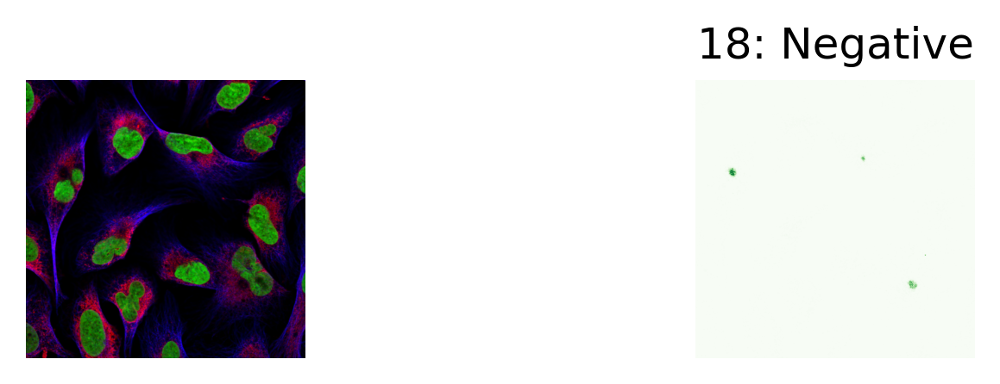

In [74]:
for index, label in enumerate(sorted(plot_images.keys())):
    label_name = LABELS[label]
    cell_image = cell_images[label]
    protein_image = protein_images[label]
    
    plt.subplot(1, 4, 1)
    plt.imshow(cell_image, origin="lower")
    plt.axis("off")

    plt.subplot(1, 4, 3)
    plt.imshow(protein_image, cmap="Greens", origin="lower")
    plt.title(f"{label}: {label_name}")
    
    plt.axis("off")
    plt.show()

In [75]:
from cellpose import models

# DEFINE CELLPOSE MODEL
# model_type='cyto' or model_type='nuclei'
# We want the cell extent so set it as cyto
model = models.Cellpose(gpu = True, model_type = 'cyto2',  device = device)

# define CHANNELS to run segementation on
# grayscale=0, R=1, G=2, B=3
# channels = [cytoplasm, nucleus]
# if NUCLEUS channel does not exist, set the second channel to 0
# channels = [0,0]
# IF ALL YOUR IMAGES ARE THE SAME TYPE, you can give a list with 2 elements
# channels = [0,0] # IF YOU HAVE GRAYSCALE
# channels = [2,3] # IF YOU HAVE G=cytoplasm and B=nucleus
# channels = [2,1] # IF YOU HAVE G=cytoplasm and R=nucleus
channels = [1, 2]

# if diameter is set to None, the size of the cells is estimated on a per image basis
# you can set the average cell `diameter` in pixels yourself (recommended) 
# diameter can be a list or a single number for all images
diameter = None

images = list(cell_images.values())

2024-03-02 13:33:10,177 [INFO] ** TORCH CUDA version installed and working. **
2024-03-02 13:33:10,179 [INFO] >>>> using GPU
2024-03-02 13:33:10,180 [INFO] >> cyto2 << model set to be used


2024-03-02 13:33:10,621 [INFO] >>>> model diam_mean =  30.000 (ROIs rescaled to this size during training)


In [76]:
# you can run all in a list e.g.
masks, flows, styles, diams = model.eval(images, diameter = diameter, channels = channels)

2024-03-02 13:33:14,227 [INFO] channels set to [1, 2]
2024-03-02 13:33:14,228 [INFO] ~~~ ESTIMATING CELL DIAMETER(S) ~~~
2024-03-02 13:33:25,466 [INFO] 100%|##########| 19/19 [00:11<00:00,  1.69it/s]
2024-03-02 13:33:25,466 [INFO] estimated cell diameter(s) in 11.24 sec
2024-03-02 13:33:25,467 [INFO] >>> diameter(s) = 
2024-03-02 13:33:25,467 [INFO] [78.32, 65.16, 72.73, 67.25, 73.34, 78.32, 65.16, 72.73, 78.32, 80.23, 79.33, 56.04, 94.76, 115.21, 102.10, 61.95, 79.33, 65.61, 81.13, ]
2024-03-02 13:33:25,467 [INFO] ~~~ FINDING MASKS ~~~
2024-03-02 13:33:40,186 [INFO] 100%|##########| 19/19 [00:14<00:00,  1.29it/s]
2024-03-02 13:33:40,187 [INFO] >>>> TOTAL TIME 25.96 sec


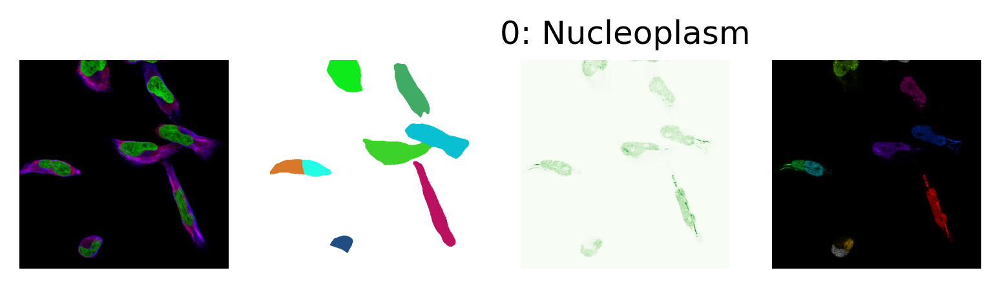

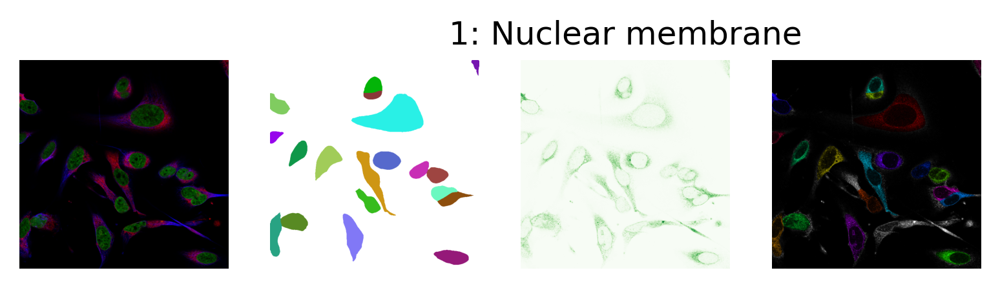

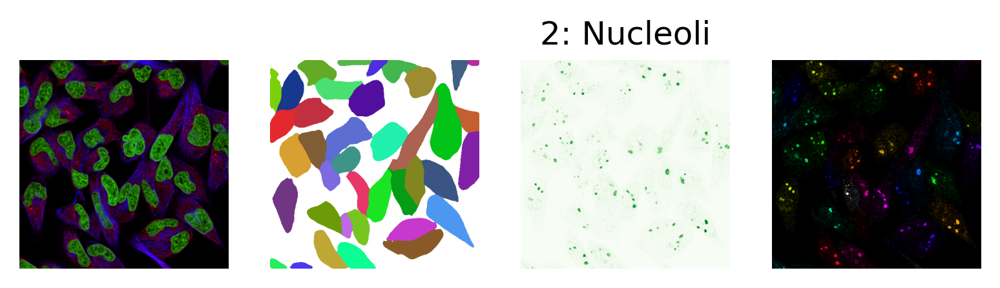

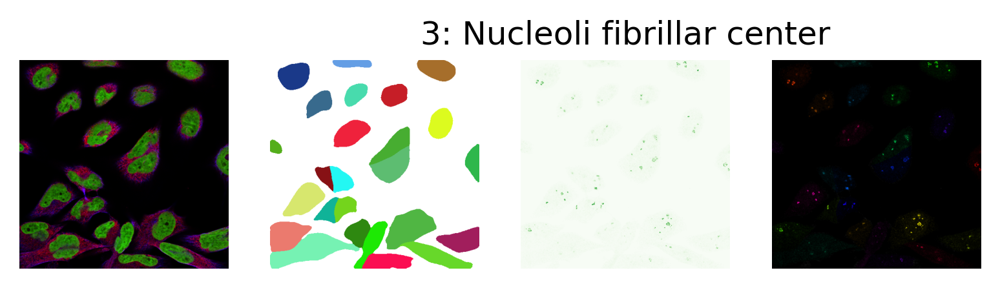

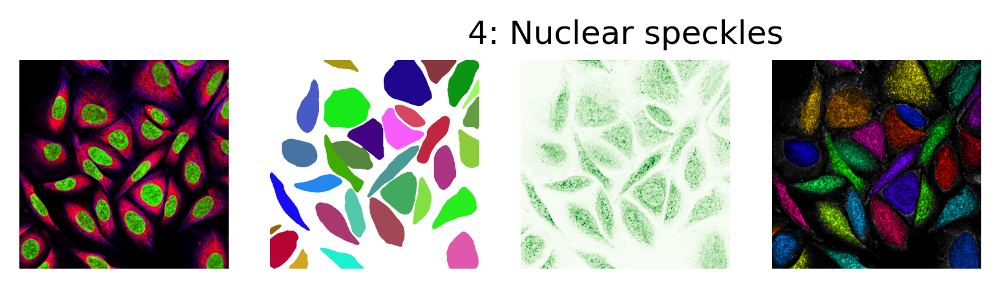

...

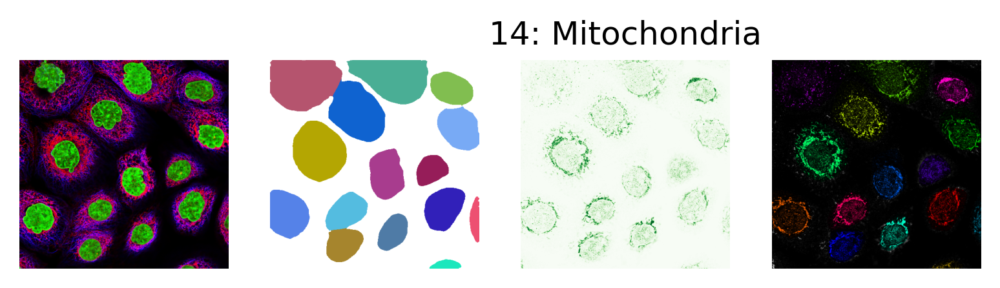

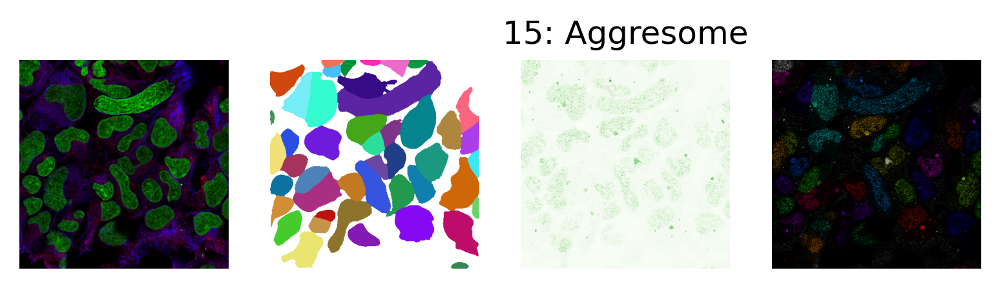

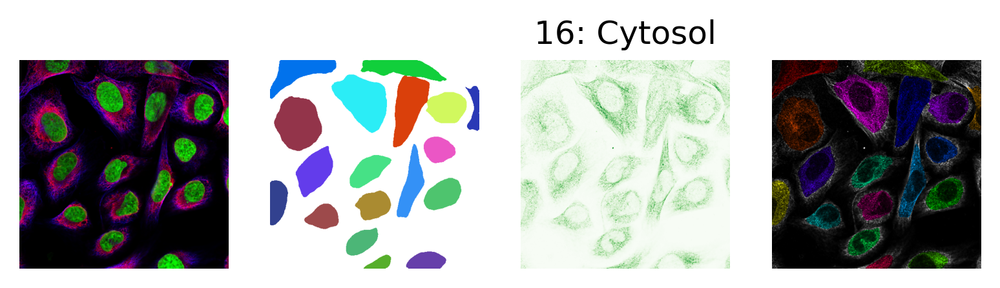

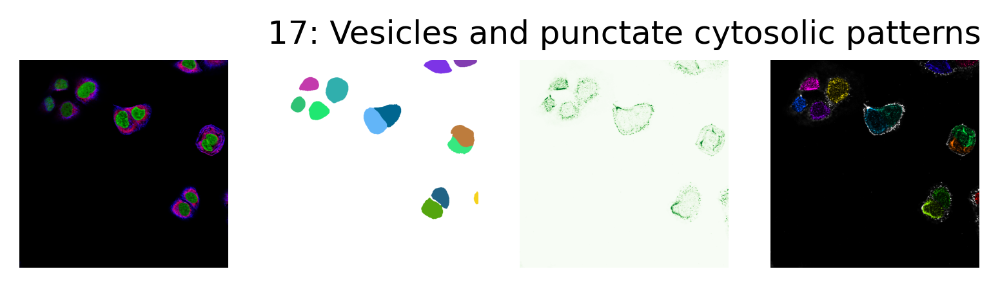

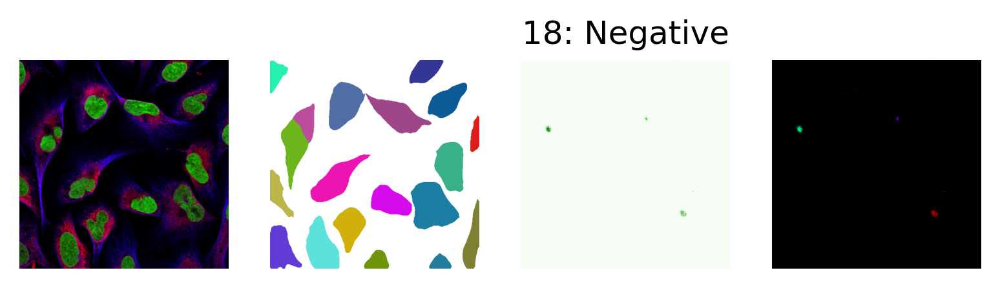

In [79]:
import cellpose
for index, label in enumerate(sorted(plot_images.keys())):
    label_name = LABELS[label]
    cell_image = cell_images[label]
    protein_image = protein_images[label]
    mask = masks[index]
    
    plt.subplot(1, 4, 1)
    plt.imshow(cell_image, origin="lower")
    plt.axis("off")
    
    plt.subplot(1, 4, 2)
    mask_image = cellpose.plot.mask_rgb(mask)
    plt.imshow(mask_image, origin="lower")
    plt.axis("off")
    
    plt.subplot(1, 4, 3)
    plt.title(f"{label}: {label_name}")
    plt.imshow(protein_image, cmap="Greens", origin="lower")
    plt.axis("off")
    
    plt.subplot(1, 4, 4)
    mask_image = cellpose.plot.mask_overlay(protein_image, mask)
    plt.imshow(mask_image, origin="lower")
    plt.axis("off")
    
    plt.show()

In [ ]:
# Comment 0: define transformation that you wish to apply on image
data_transforms_no_norm = transforms.Compose([transforms.ToTensor(),
     transforms.Resize((32,32))])
# Comment 1 : Load the datasets with ImageFolder
trainset_no_norm = datasets.ImageFolder(root= PATH_OF_DATA+"/Train_Nums",
                                      transform=data_transforms_no_norm)
# Comment 2: Using the image datasets and the transforms, define the dataloaders
train_sampler_no_norm = torch.utils.data.RandomSampler(trainset_no_norm)
trainloader_no_norm = torch.utils.data.DataLoader(trainset_no_norm, batch_size=4, sampler = train_sampler_no_norm, shuffle=False, num_workers=2)

testset_no_norm = datasets.ImageFolder(root=PATH_OF_DATA+"/Test_Nums",
                               transform=data_transforms_no_norm)
testloader_no_norm = torch.utils.data.DataLoader(testset_no_norm, batch_size=4, shuffle=False, num_workers=2)

In [ ]:
import torch.nn as nn
import torch.nn.functional as F

class Net(nn.Module):
    def __init__(self):
        super(Net, self).__init__()
        self.conv1 = nn.Conv2d(3, 6, 5)
        self.pool = nn.MaxPool2d(2, 2)
        self.conv2 = nn.Conv2d(6, 16, 5)
        self.fc1 = nn.Linear(16 * 5 * 5, 120)
        self.fc2 = nn.Linear(120, 32)
        self.fc3 = nn.Linear(32, 10)

    def forward(self, x):
        x = self.pool(F.relu(self.conv1(x)))
        x = self.pool(F.relu(self.conv2(x)))
        x = x.view(-1, 16 * 5 * 5)   # flatten features

        x = F.relu(self.fc1(x))
        x = F.relu(self.fc2(x))
        x = self.fc3(x)
        return x

net = Net()

In [ ]:
# Define the CNN model
class SimpleCNN(nn.Module):
    def __init__(self, num_classes):
        super(SimpleCNN, self).__init__()
        self.resnet18 = resnet18(pretrained=True)
        in_features = self.resnet18.fc.in_features
        self.resnet18.fc = nn.Linear(in_features, num_classes)

    def forward(self, x):
        return self.resnet18(x)

# Initialize the model, loss function, and optimizer
model = SimpleCNN(num_classes=len(mlb.classes_))
criterion = nn.BCEWithLogitsLoss()
optimizer = optim.Adam(model.parameters(), lr=0.001)
scheduler = ReduceLROnPlateau(optimizer, mode='min', patience=3, verbose=True)

# Train the model
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model.to(device)

%pip install torchsummary
from torchsummary import summary

summary(model, (3, 224, 224))  # Print model summary

epochs = 10
for epoch in range(epochs):
    model.train()
    for images, labels in train_loader:
        images, labels = images.to(device), labels.to(device)
        optimizer.zero_grad()
        outputs = model(images)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()

    # Validate the model
    model.eval()
    val_loss = 0.0
    with torch.no_grad():
        for images, labels in val_loader:
            images, labels = images.to(device), labels.to(device)
            outputs = model(images)
            val_loss += criterion(outputs, labels).item()

    val_loss /= len(val_loader)
    print(f"Epoch {epoch+1}/{epochs}, Validation Loss: {val_loss}")
    scheduler.step(val_loss)

# Save the model for future use
torch.save(model.state_dict(), 'final_single_cell_classification_model.pth')

In [ ]:
# Comment 0: define transformation that you wish to apply on image
data_transforms_no_norm = transforms.Compose([transforms.ToTensor(),
     transforms.Resize((512, 512))])
# Comment 1 : Load the datasets with ImageFolder
trainset_no_norm = datasets.ImageFolder(root = PATH_OF_DATA,
                                      transform = data_transforms_no_norm)
# Comment 2: Using the image datasets and the transforms, define the dataloaders
train_sampler_no_norm = torch.utils.data.RandomSampler(trainset_no_norm)
trainloader_no_norm = torch.utils.data.DataLoader(trainset_no_norm, batch_size = 4, sampler = train_sampler_no_norm, shuffle = False, num_workers = 2)

testset_no_norm = datasets.ImageFolder(root = PATH_OF_DATA+"/Test_Nums",
                               transform = data_transforms_no_norm)
testloader_no_norm = torch.utils.data.DataLoader(testset_no_norm, batch_size = 4, shuffle = False, num_workers = 2)